# работа метода на разных аргах (симуляция + восстановленные через relate и tsinfer)

In [ ]:
import shutil
import os
import numpy as np
import matplotlib.pyplot as plt
import contextlib
import sys
import tqdm

In [1]:
from demo import TS_sim, TS_tsinfer, TS_relate

In [3]:

@contextlib.contextmanager
def suppress_output():
    devnull = os.open(os.devnull, os.O_WRONLY)

    old_stdout = os.dup(1)
    old_stderr = os.dup(2)

    os.dup2(devnull, 1)
    os.dup2(devnull, 2)

    try:
        yield
    finally:
        os.dup2(old_stdout, 1)
        os.dup2(old_stderr, 2)

        os.close(old_stdout)
        os.close(old_stderr)
        os.close(devnull)

In [4]:
t_BCD = 10
tBC_vals = list(range(10, 500, 20))
selected_tBC = [30, 90, 150, 210, 310, 450]
admix_ratios = [0.25, 0.5, 0.75]

ts_types = ["sim", "tsi", "rel"]

cols = {
    "sim" : {
        0.25: '#FFDBAA', 
        0.5: 'tan', 
        0.75: '#A38C6D'
    },
    "rel": {
        0.25: '#8370FF', 
        0.5: 'slateblue', 
        0.75: '#4F4399'       
    },
    "tsi": {
        0.25: '#FF83FA', 
        0.5: 'orchid', 
        0.75: '#B25CAF'       
    }
}

mse = {r: {ts: {t: 0 for t in tBC_vals} for ts in ts_types} for r in admix_ratios+["all"]}

## визуализация отработки симуляций

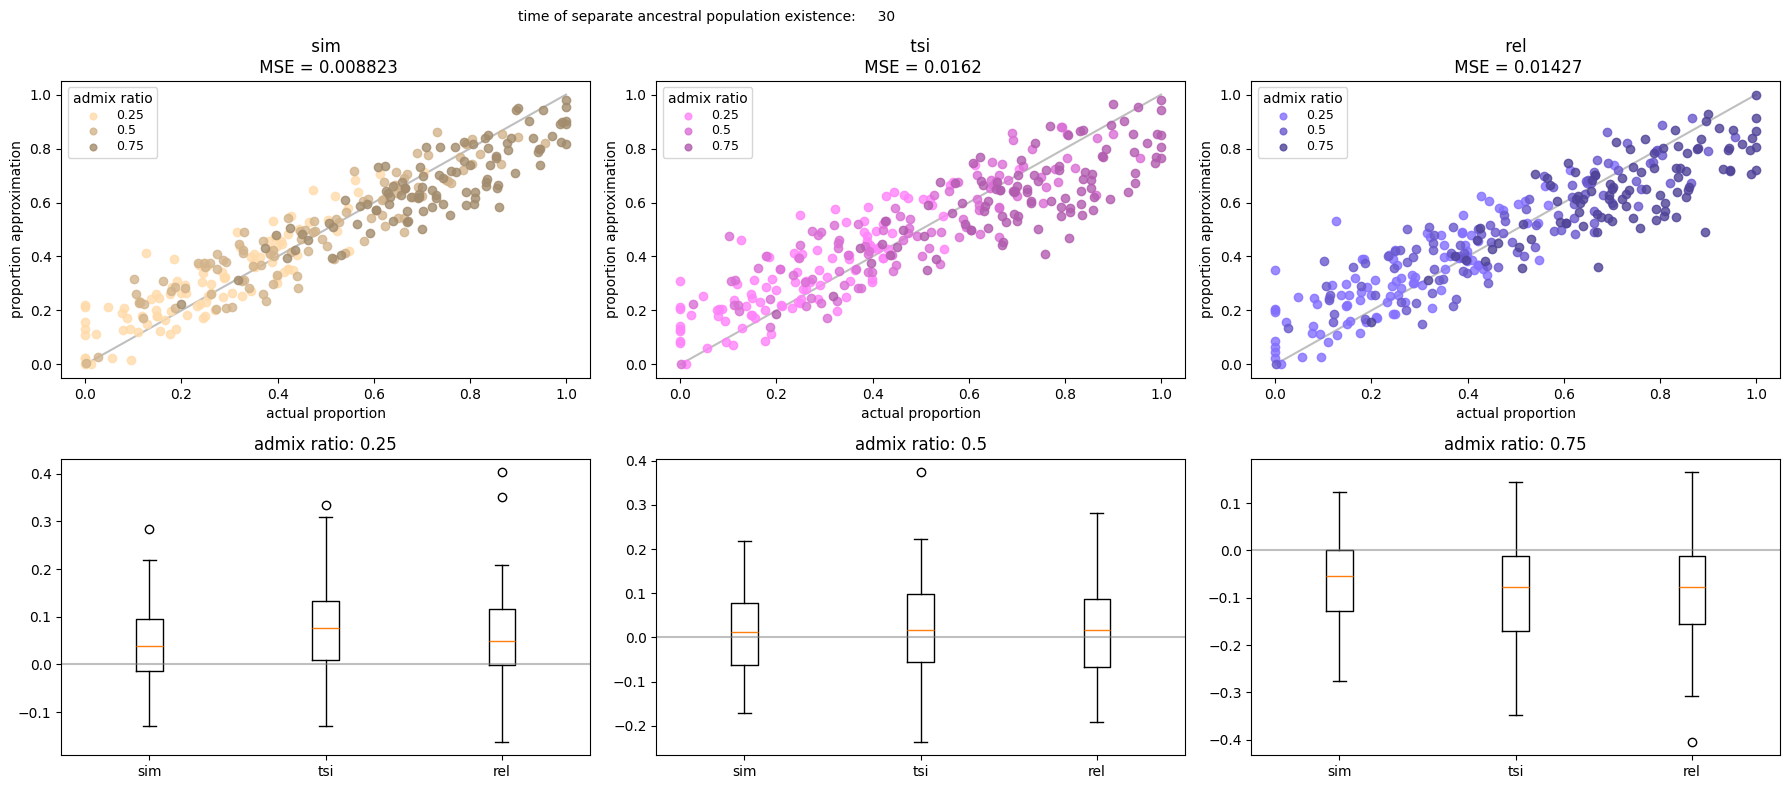

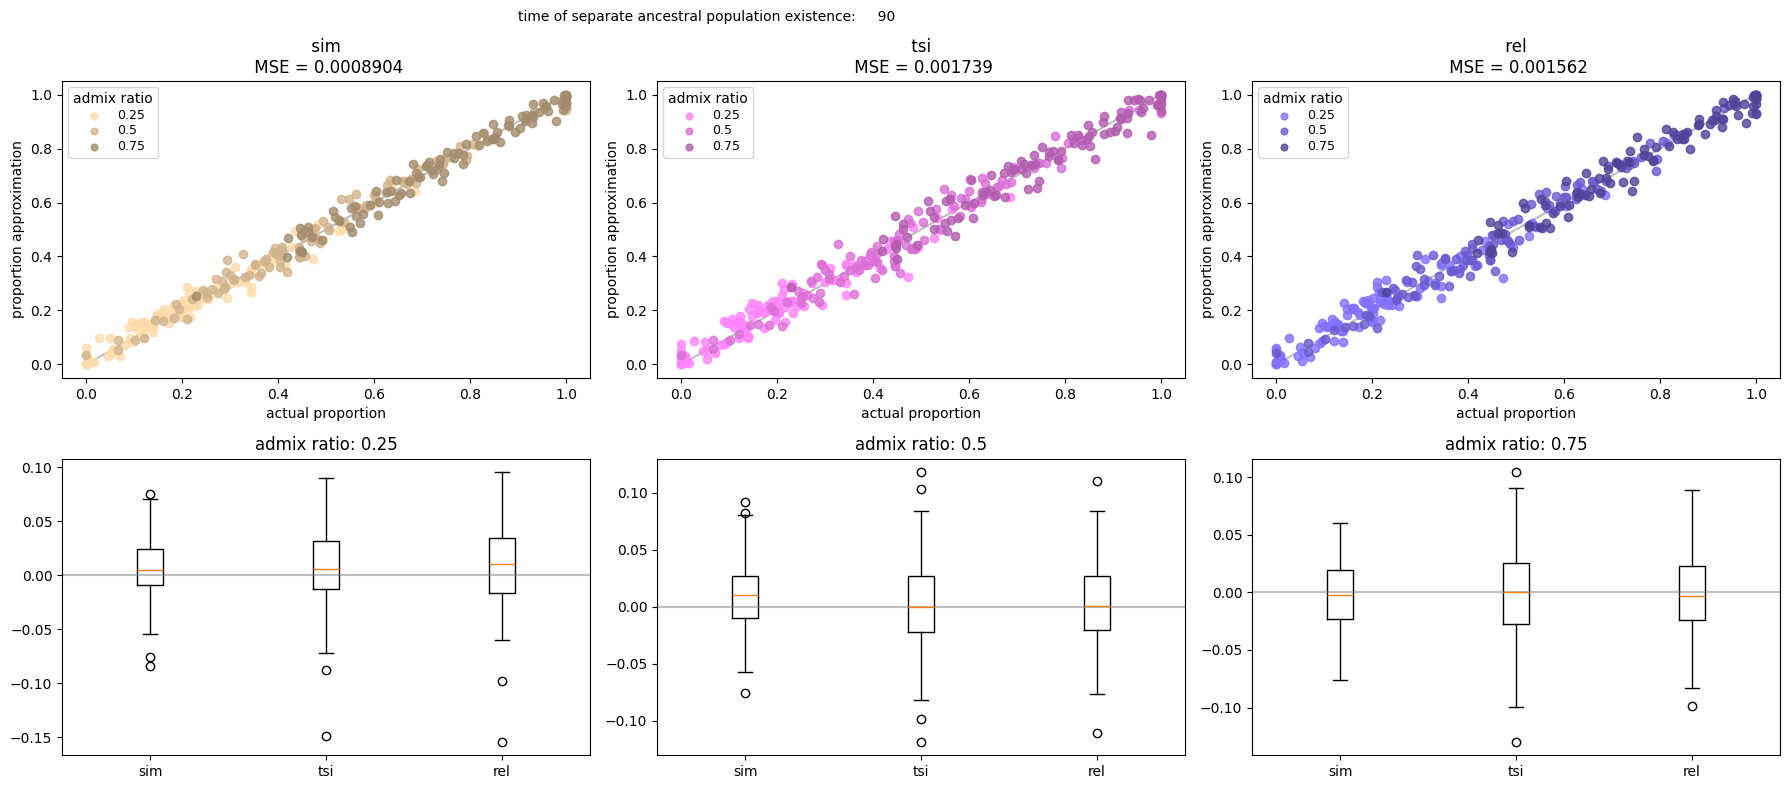

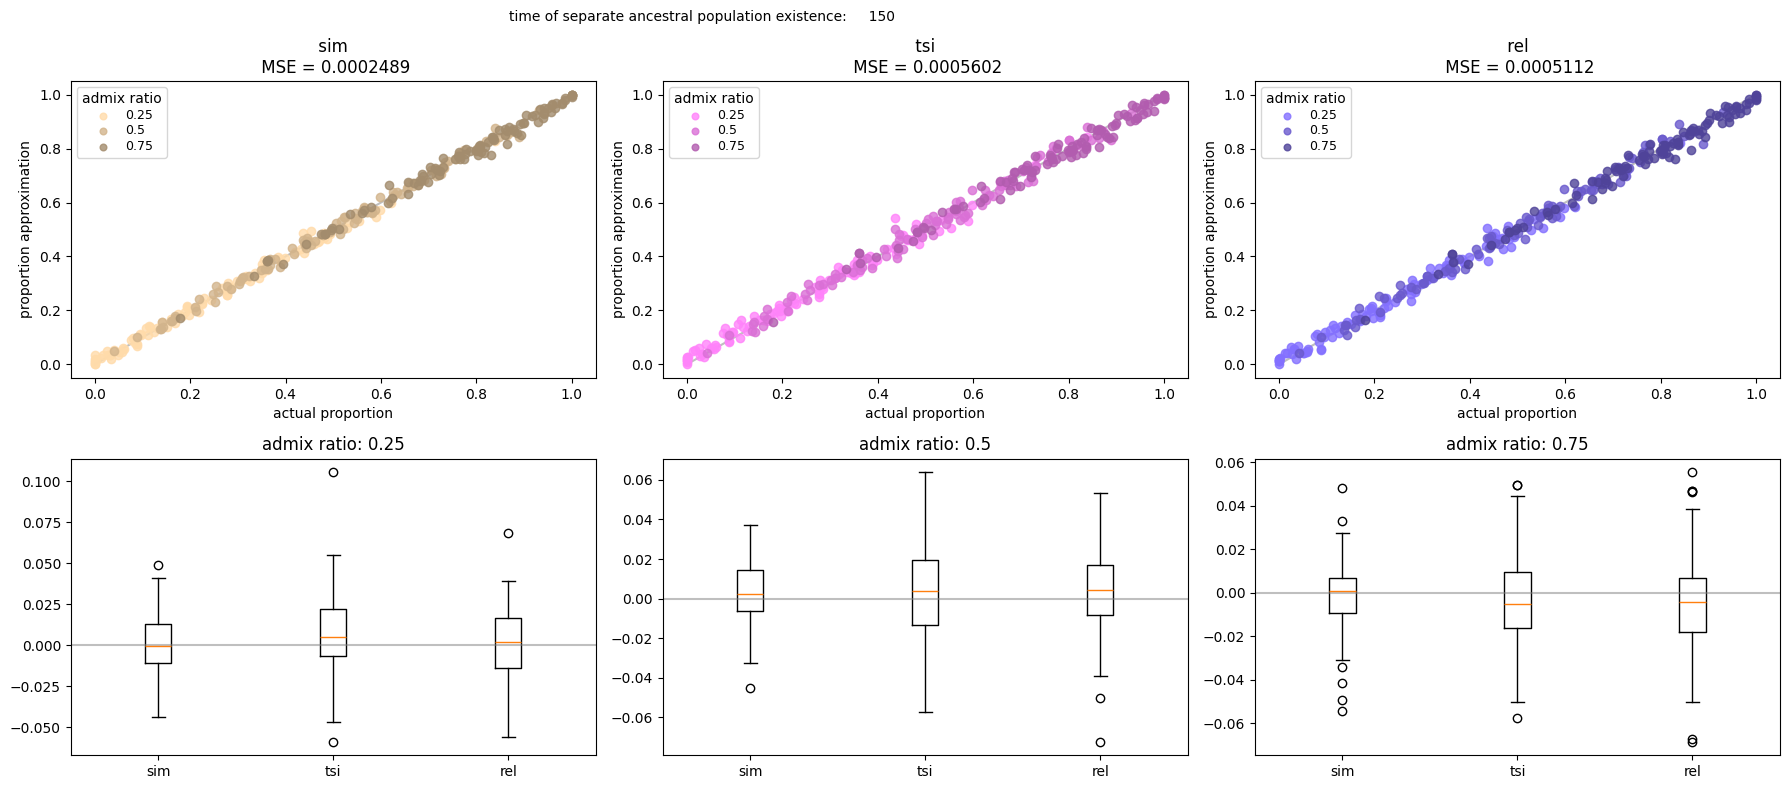

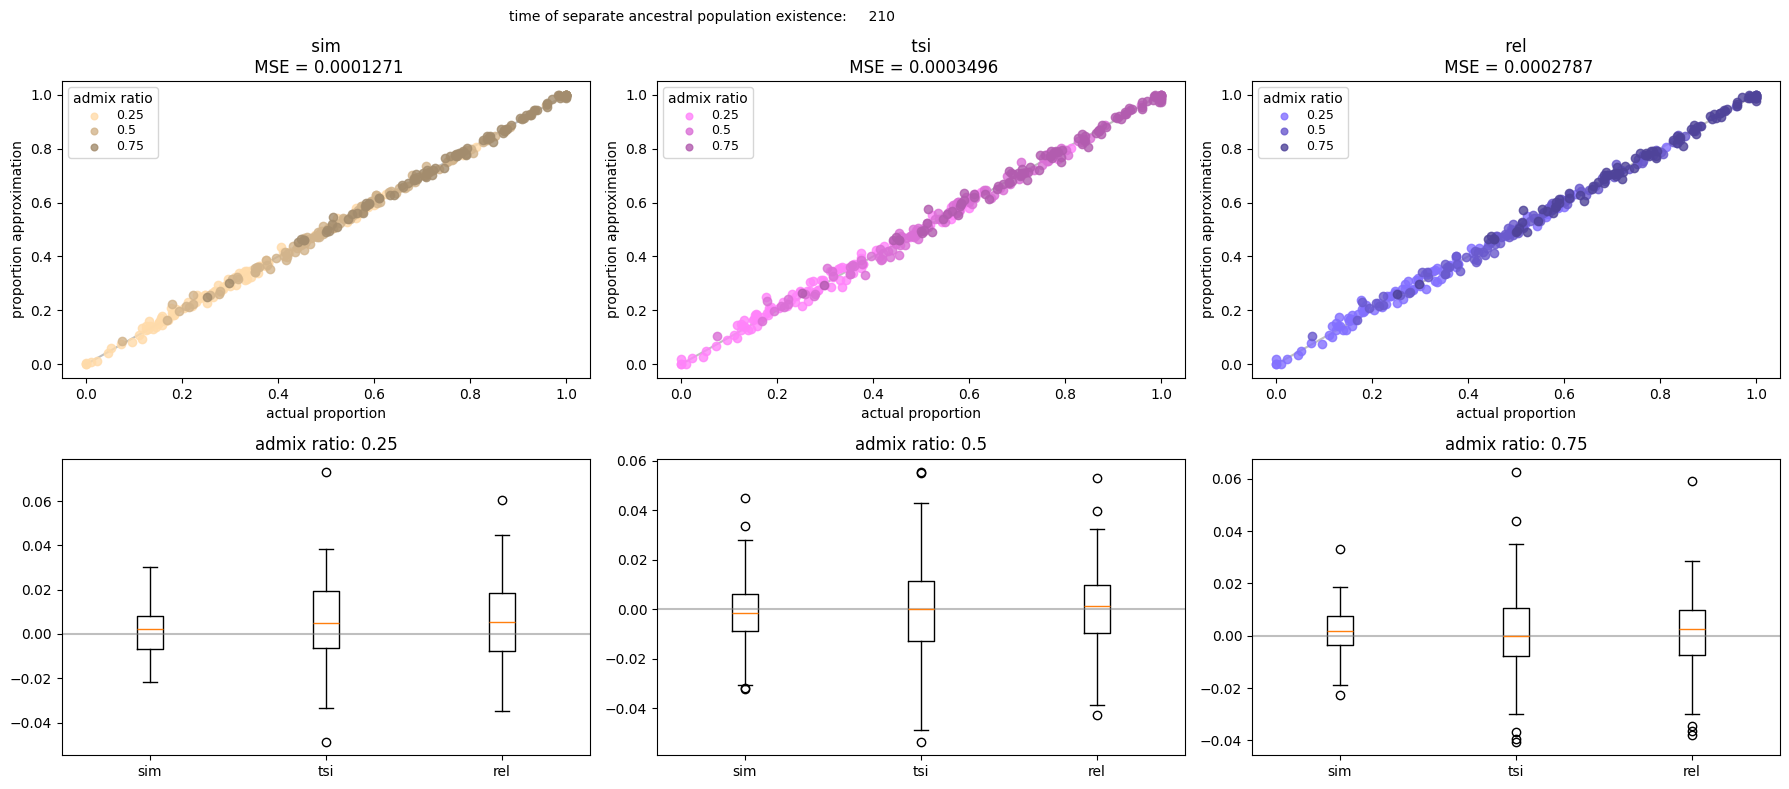

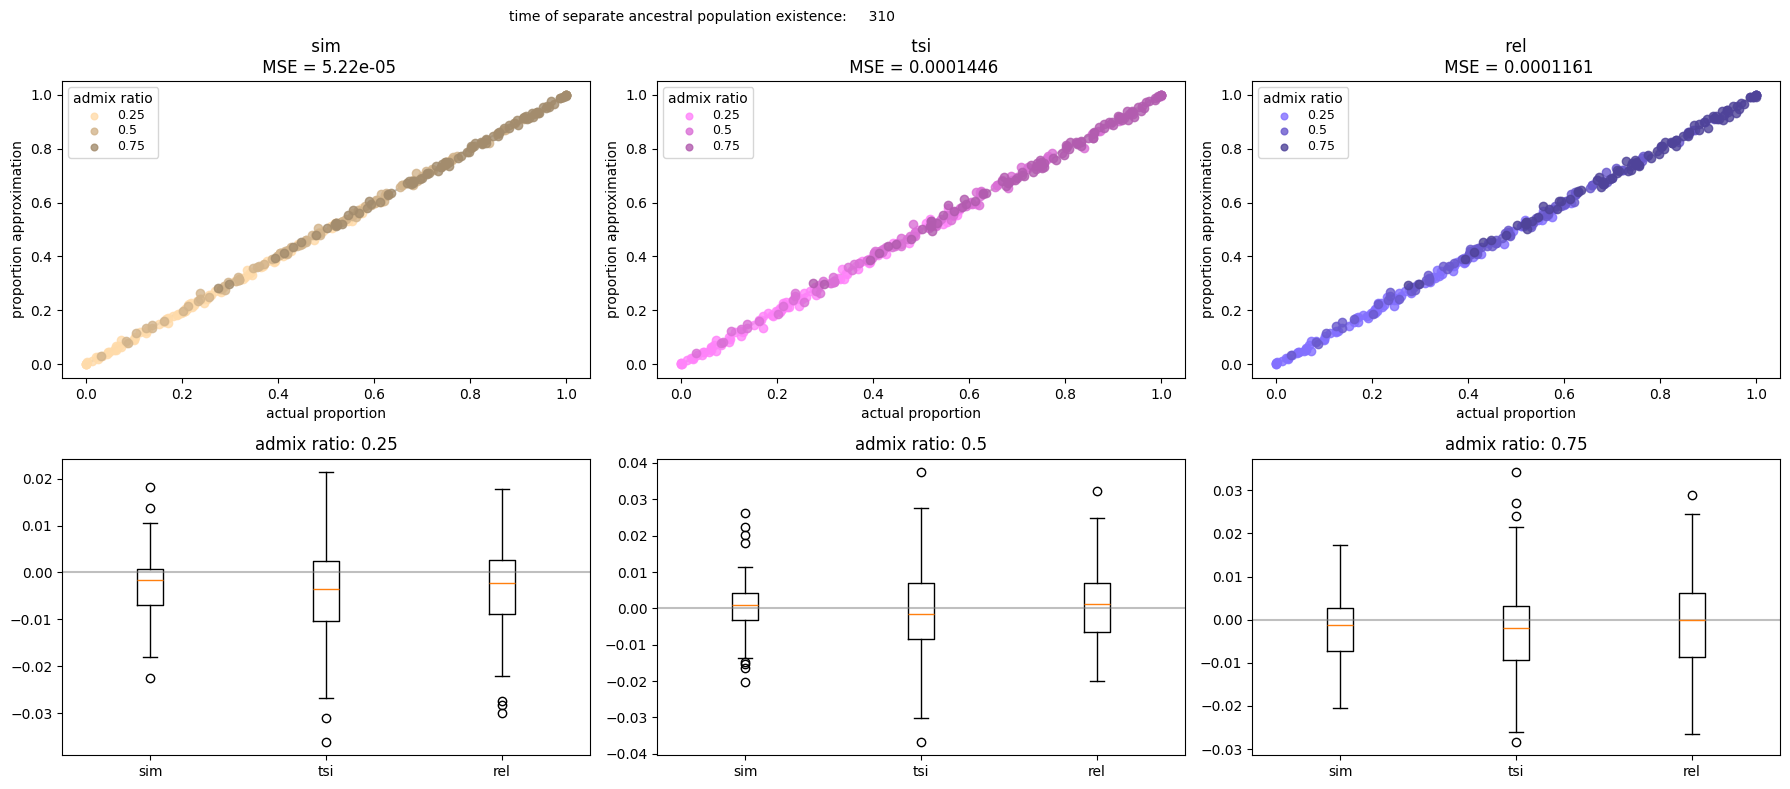

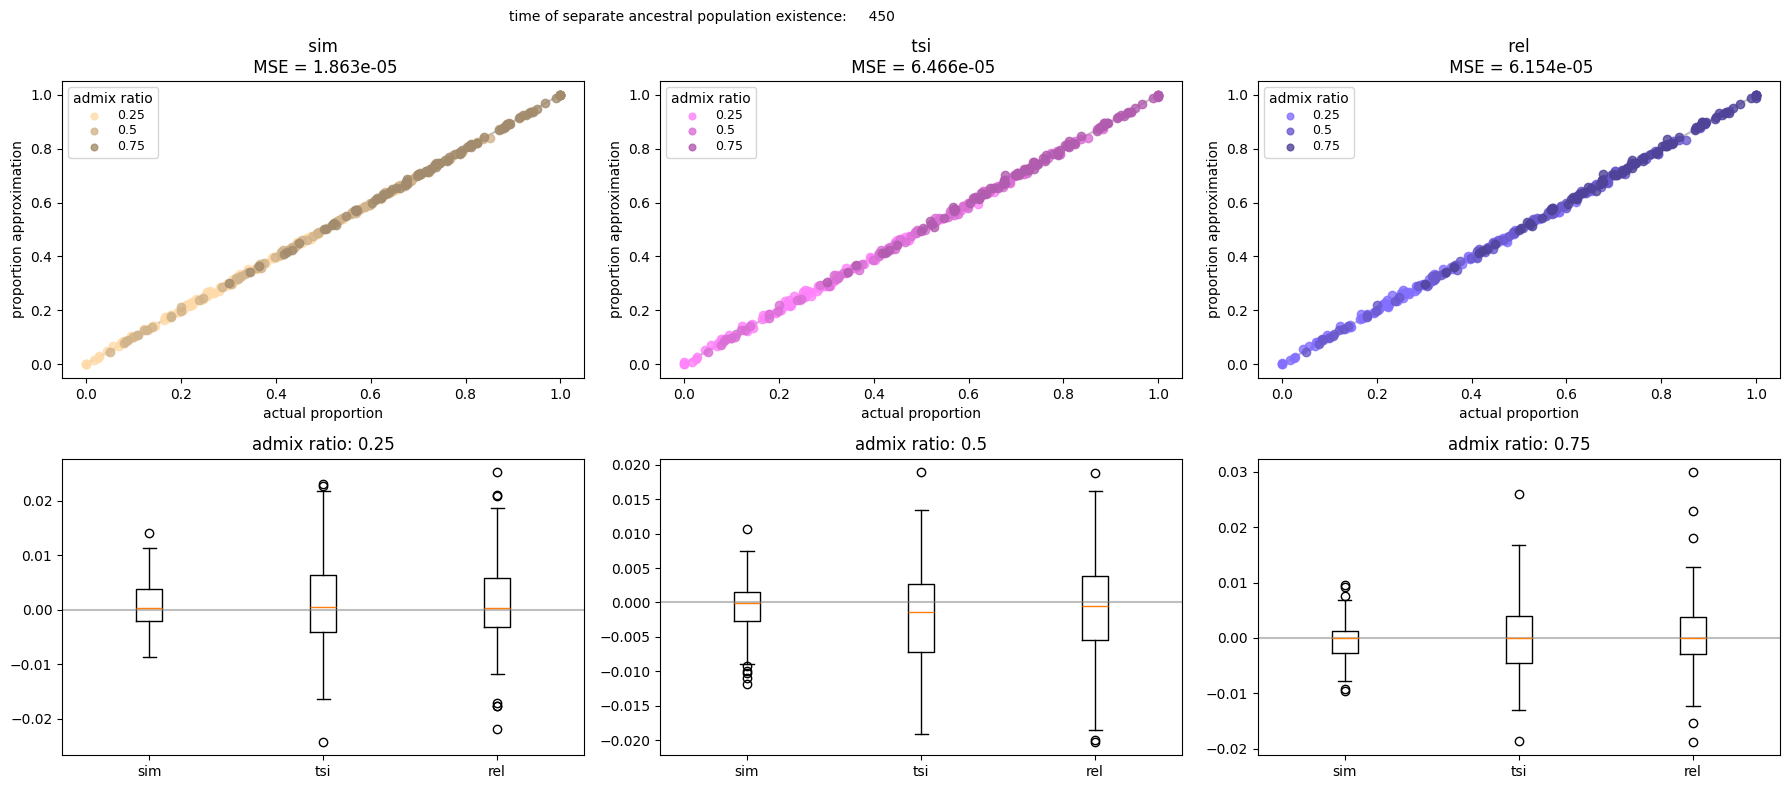

In [5]:
for t_BC in tBC_vals:
    flag = 0
    if t_BC in selected_tBC:
        flag = 1
        fig, ax = plt.subplots(2, 3, figsize=(18, 8))
        fig.suptitle(f'time of separate ancestral population existence:     {t_BC}', ha='right', fontsize='medium')

    for j, ratio in enumerate(admix_ratios):
        sim = TS_sim(t_anc=t_BC, t_new=t_BCD,
                     admix_ratio=[ratio, 1-ratio])
        with suppress_output():
            run_dir = sim.save_vcf()
            tsi = TS_tsinfer(sim, run_dir)
            rel = TS_relate(sim, run_dir)
            shutil.rmtree(run_dir)

        for i, ts_name, model in zip(range(3), ts_types, [sim, tsi, rel]):
            model.anc_cnt()
            alpha, _ = model.targ_appr()
            true = model.true_ancestry[:,0]
            approx = alpha[:,0]
            mse_val = np.mean((approx - true)**2)
            mse[ratio][ts_name][t_BC] = mse_val
            mse["all"][ts_name][t_BC] += mse_val/3

            if flag:
                ax[0,i].scatter(true, approx, label=f'{ratio}', c=cols[ts_name][ratio], alpha=0.8)
                ax[1,j].boxplot(approx-true, positions=[i])
    
    if flag:
        for i in range(3):
            ax[0,i].set_title(f' {ts_types[i]} \n MSE = {mse["all"][ts_types[i]][t_BC]:.4}')
            ax[0,i].set_xlabel('actual proportion')
            ax[0,i].set_ylabel('proportion approximation')
            ax[0,i].legend(title="admix ratio", fontsize=9, markerscale=0.8, labelspacing=0.2)
            ax[0,i].plot([0,1], [0,1], color='grey', alpha=0.5, zorder=0)
            
            ax[1,i].set_title(f'admix ratio: {admix_ratios[i]}')
            ax[1,i].axhline(y=0, color='grey', alpha=0.5)
            ax[1,i].set_xticklabels(ts_types)

        plt.tight_layout()
        plt.show()

## поведение ошибки при изменении времени разделения

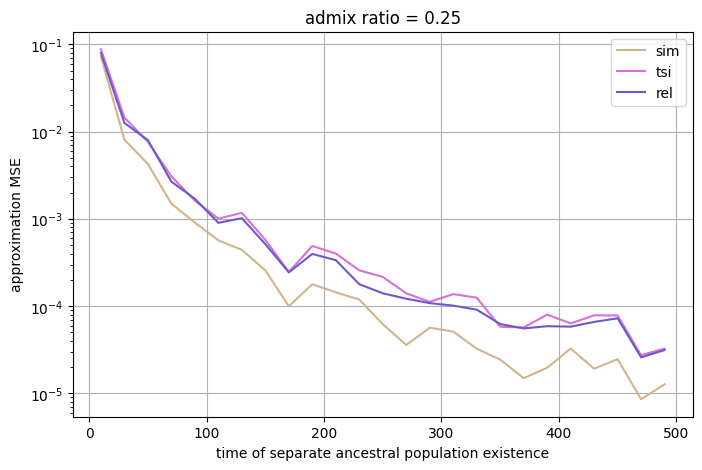

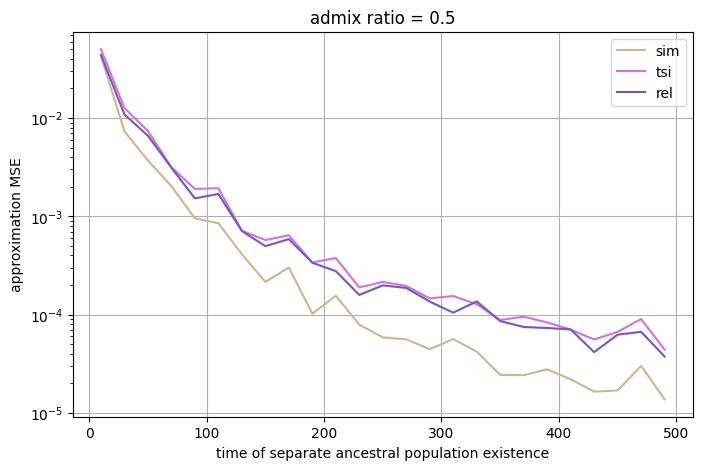

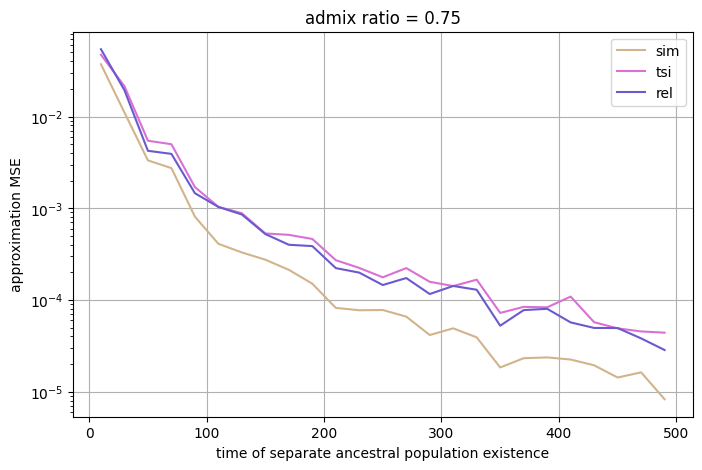

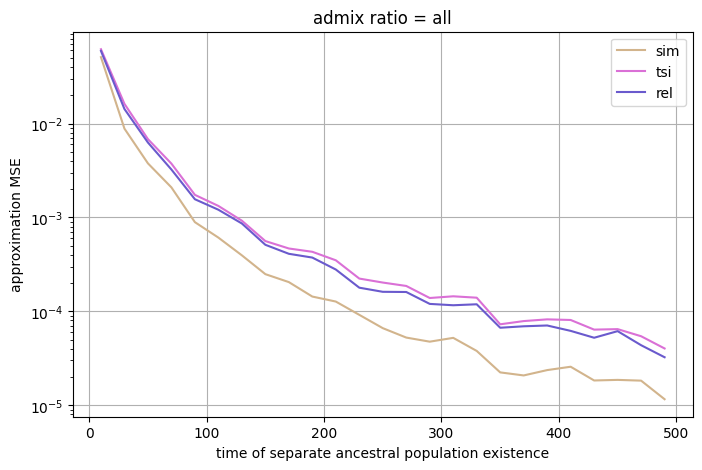

In [6]:
for ratio in admix_ratios + ["all"]:
    fig, ax = plt.subplots(figsize=(8,5))
    for ts_name in ts_types:
        t_values = sorted(tBC_vals)
        mse_values = [mse[ratio][ts_name][t] for t in t_values]
        ax.plot(t_values, mse_values, label=ts_name, c=cols[ts_name][0.5])
    
    ax.set_xlabel("time of separate ancestral population existence")
    ax.set_ylabel("approximation MSE")
    ax.set_title(f"admix ratio = {ratio}")
    ax.set_yscale('log')
    ax.grid(zorder=0)
    ax.legend()
    plt.show()

# сравнение с admixture

In [7]:
import shutil
import os
import numpy as np
import matplotlib.pyplot as plt
import contextlib
import subprocess
import timeit
from datetime import datetime

from demo import TS_sim, TS_tsinfer, TS_relate

In [8]:
@contextlib.contextmanager
def suppress_output():
    devnull = os.open(os.devnull, os.O_WRONLY)

    old_stdout = os.dup(1)
    old_stderr = os.dup(2)

    os.dup2(devnull, 1)
    os.dup2(devnull, 2)

    try:
        yield
    finally:
        os.dup2(old_stdout, 1)
        os.dup2(old_stderr, 2)

        os.close(old_stdout)
        os.close(old_stderr)
        os.close(devnull)

colors = {
            'relate': 'slateblue',
            'tsinfer': 'orchid',
            'admixture': 'olivedrab'
        }


def compare(t_BC=100, t_BCD=10, admix_ratio=0.5, size=1000, tsi=False, show_results=False, log=False, clear=True):
    def log_msg(message):
        if log:
            print(f"[{datetime.now().strftime('%H:%M:%S')}] {message}", flush=True)

    time = dict()
    approx = dict()

    log_msg("simulating data")

    sim = TS_sim(t_anc=t_BC, t_new=t_BCD,
                admix_ratio=[admix_ratio, 1-admix_ratio], 
                size_com = size, size_anc=[size] * 2, size_new = size)
    
    log_msg("saving vcf file")
    with suppress_output():
        run_dir = sim.save_vcf()
    true = sim.true_ancestry[:,0]
    true = (true[0::2] + true[1::2]) / 2

    log_msg("data is ready for analysis\n")
    
    
    if tsi:
        s = timeit.default_timer()
        log_msg("inferring the tree with tsinfer")
        with suppress_output():
            tsi = TS_tsinfer(sim, run_dir)
        log_msg("counting ancestry for the tsinfer tree")
        tsi.anc_cnt()
        alpha, _ = tsi.targ_appr()
        approx_tsinfer = alpha[:,0]
        approx['tsinfer'] = (approx_tsinfer[0::2] + approx_tsinfer[1::2]) / 2
        e = timeit.default_timer()
        log_msg("tsinfer tree analysis finished\n")
        time['tsinfer'] = e - s

    s = timeit.default_timer()
    log_msg("inferring the tree with relate")
    with suppress_output():
        rel = TS_relate(sim, run_dir)
    log_msg("counting ancestry for the relate tree")
    rel.anc_cnt()
    alpha, _ = rel.targ_appr()
    approx_relate = alpha[:,0]
    approx['relate'] = (approx_relate[0::2] + approx_relate[1::2]) / 2
    e = timeit.default_timer()
    log_msg("relate tree analysis finished\n")
    time['relate'] = e - s

    s = timeit.default_timer()
    log_msg("preparing data for ADMIXTURE using plink")
    with suppress_output():
        subprocess.run([
                "plink/plink", "--vcf",
                run_dir + "/sim.vcf.gz",
                "--double-id", "--make-bed", "--out",
                run_dir + "/sim"
                ], check=True)
    
    log_msg("creating .pop file")
    pop = ['-'] * sim.N
    cur_id = 0
    for i in range (sim.anc_pops):
        cur_pop = 'POP' + str(i + 1)
        for j in range(sim.N_samples[i]):
            pop[cur_id] = cur_pop
            cur_id += 1


    with open(run_dir + "/sim.pop", "w") as f:
        f.write("\n".join(pop))

    log_msg("starting ADMIXTURE")
    attempt = 1
    admixture_success = False
    while attempt <= 3 and not admixture_success:
        log_msg(f"  ADMIXTURE attempt {attempt}")
        try:
            with suppress_output():
                subprocess.run([
                    "dist/admixture_macosx-1.3.0/admixture",
                    "--supervised",
                    run_dir + "/sim.bed",
                    str(sim.anc_pops)
                    ], check=True)
            admixture_success = True
            log_msg("       ADMIXTURE finished")
        except Exception as e:
            log_msg(f"      ADMIXTURE failed with error: {e}")
            admixture_success = False
    e = timeit.default_timer()
    time['admixture'] = e - s
    if admixture_success:
        a = np.loadtxt('sim.2.Q')
        if a[:50,0].sum() > a[:50,1].sum():
            approx_admixture = a[100:,0]
        else:
            approx_admixture = a[100:,1]
        approx['admixture'] = approx_admixture
        log_msg("ADMIXTURE data saved\n")
    else:
        log_msg("all ADMIXTURE attempts failed\n")
        approx['admixture'] = None


    if clear:
        shutil.rmtree(run_dir)
        os.remove('sim.2.Q')
        os.remove('sim.2.P')
        log_msg("all data cleared\n\n")


    if show_results:
        labels=['relate']
        if tsi:
            labels.append('tsinfer')
        if admixture_success:
            labels.append('admixture')
        fig, ax = plt.subplots(2, figsize=(8, 10))

        for i, lab in enumerate(labels):
            t = time[lab]
            t_int = int(t) // 60
            h = t_int // 60
            m = t_int % 60
            s = t - h * 3600 - m * 60
            t_str = f'{m} min {s:.2f} s'
            if h > 0:
                t_str = f'{h} h' + t_str
            print(f'method using {lab} took ' + t_str)
            ax[0].scatter(true, approx[lab], label=lab, alpha=0.8, c=colors[lab])
            ax[1].boxplot(approx[lab]-true, positions=[i])

        
        ax[0].plot([0,1], [0,1], color='grey', alpha=0.5)
        ax[0].legend()
        ax[0].set_title('Results of Approximation for each Algorithm')
        ax[0].set_xlabel('actual proportion')
        ax[0].set_ylabel('proportion approximation')
        ax[1].set_title('Difference between the Approximation and Actual Proportion')
        ax[1].axhline(y=0, color='grey', alpha=0.5)
        ax[1].set_xticklabels(labels)
        fig.suptitle(f'time of separate ancestral population existence:     {t_BC}\n'+
                     f'admixture ratio:     {admix_ratio}\n'+
                     f'population size:     {size}', 
                     ha='right', fontsize='medium')
        plt.show()

    return true, approx, time

## проверка связи

[19:24:43] simulating data
[19:24:51] saving vcf file
[19:25:02] data is ready for analysis

[19:25:02] inferring the tree with tsinfer
[19:25:47] counting ancestry for the tsinfer tree
[19:27:23] tsinfer tree analysis finished

[19:27:23] inferring the tree with relate
[19:29:11] counting ancestry for the relate tree
[19:29:27] relate tree analysis finished

[19:29:27] preparing data for ADMIXTURE using plink
[19:29:27] creating .pop file
[19:29:27] starting ADMIXTURE
[19:29:27]   ADMIXTURE attempt 1
[19:30:39]        ADMIXTURE finished
[19:30:39] ADMIXTURE data saved

[19:30:39] all data cleared


method using relate took 2 min 3.68 s
method using tsinfer took 2 min 20.90 s
method using admixture took 1 min 12.47 s


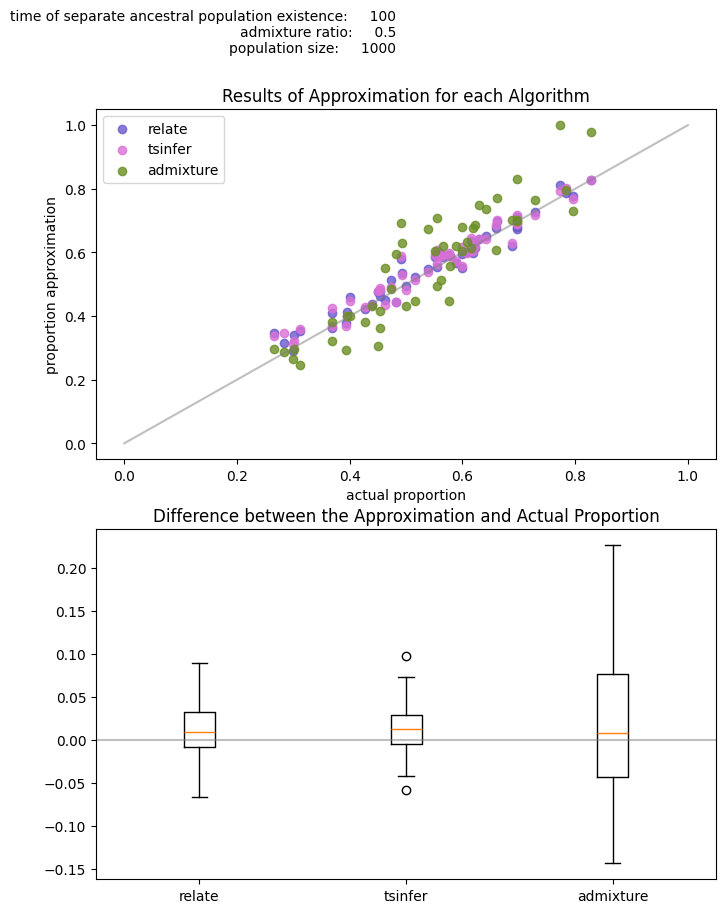

In [3]:
true, approx, time = compare(show_results=True, tsi=True,log=True)

## тестирование для больших популяций ($N_e = 10^4$)

[19:30:39] simulating data
[19:32:57] saving vcf file
[19:34:19] data is ready for analysis

[19:34:19] inferring the tree with tsinfer
[19:55:54] counting ancestry for the tsinfer tree
[20:26:22] tsinfer tree analysis finished

[20:26:22] inferring the tree with relate
[20:43:39] counting ancestry for the relate tree
[20:46:01] relate tree analysis finished

[20:46:01] preparing data for ADMIXTURE using plink
[20:46:03] creating .pop file
[20:46:03] starting ADMIXTURE
[20:46:03]   ADMIXTURE attempt 1
[21:28:55]        ADMIXTURE finished
[21:28:55] ADMIXTURE data saved

[21:28:55] all data cleared


method using relate took 19 min 38.77 s
method using tsinfer took 34 min 42.13 s
method using admixture took 42 min 53.31 s


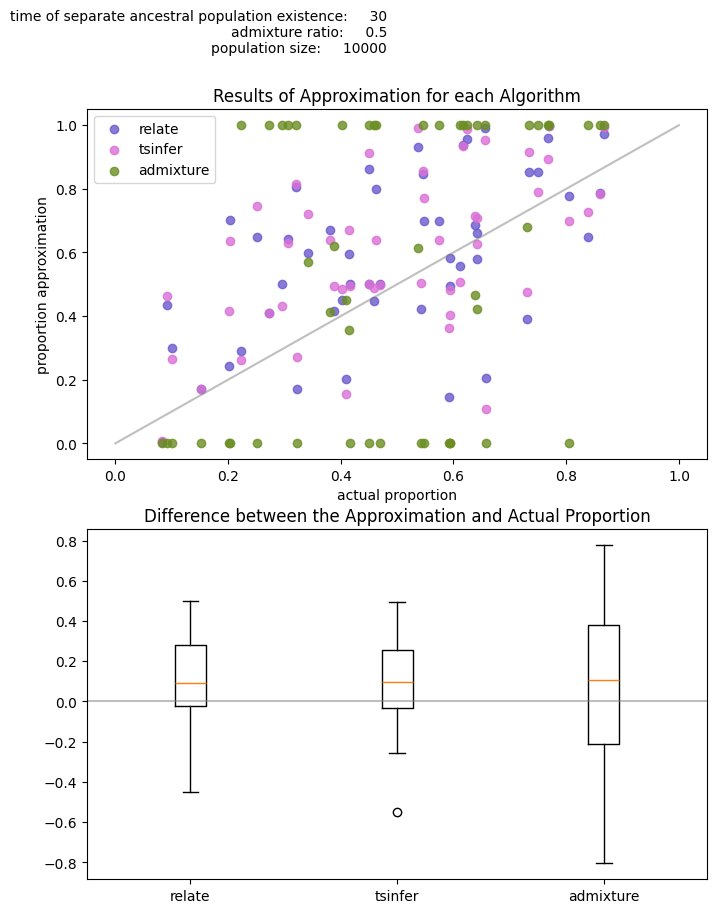

In [4]:
true, approx, time = compare(t_BC=30, t_BCD=5, size=10000, tsi=True, show_results=True, log=True)

[21:28:56] simulating data
[21:31:22] saving vcf file
[21:32:55] data is ready for analysis

[21:32:55] inferring the tree with tsinfer
[21:51:04] counting ancestry for the tsinfer tree
[21:59:25] tsinfer tree analysis finished

[21:59:25] inferring the tree with relate
[22:10:39] counting ancestry for the relate tree
[22:12:07] relate tree analysis finished

[22:12:07] preparing data for ADMIXTURE using plink
[22:12:09] creating .pop file
[22:12:09] starting ADMIXTURE
[22:12:09]   ADMIXTURE attempt 1
[22:18:06]        ADMIXTURE finished
[22:18:06] ADMIXTURE data saved

[22:18:07] all data cleared


method using relate took 12 min 42.11 s
method using tsinfer took 26 min 29.87 s
method using admixture took 5 min 58.77 s


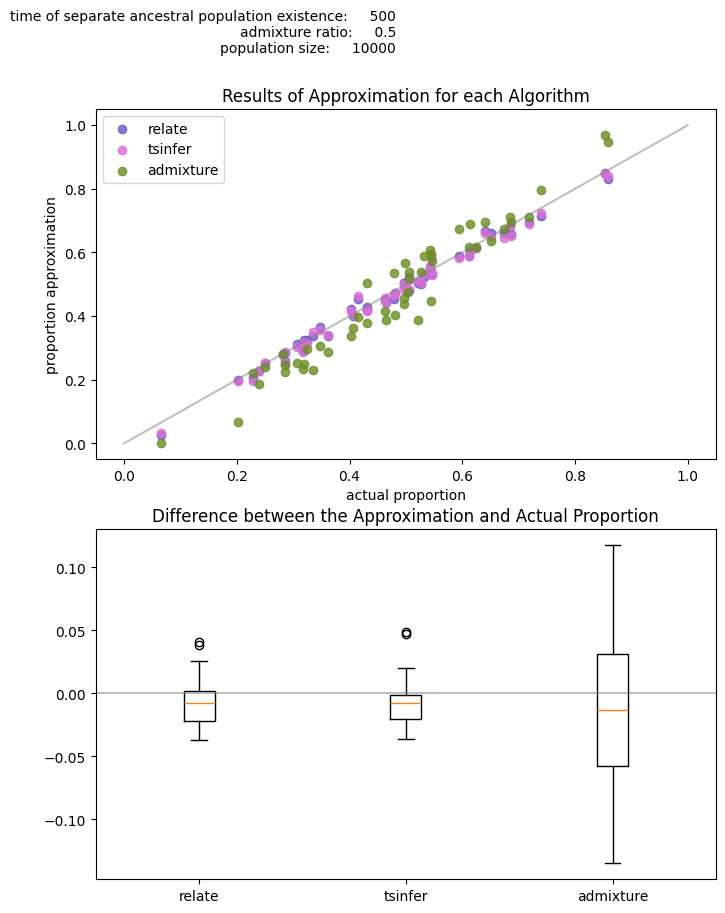

In [5]:
true, approx, time = compare(t_BC=500, t_BCD=5, size=10000, tsi=True, show_results=True, log=True)

## сравнение методов для разного времени разделения

In [9]:
from tqdm import tqdm

tBC_vals = list(range(10, 800, 10))

times = dict()
errors = dict()

labels = ['relate', 'admixture', 'tsinfer']
for lab in labels:
    times[lab] = []
    errors[lab] = []

admixture_fail = []

for t_BC in tqdm(tBC_vals):
    admix_ratio = np.random.uniform(0.3, 0.7)
    true, approx, time = compare(t_BC=t_BC, admix_ratio=admix_ratio, tsi=True)
    for lab in labels:
        times[lab].append(time[lab])
        if approx[lab] is None:
            errors[lab].append(1)
            if lab == 'admixture':
                admixture_fail.append(t_BC)
        else:
            mse = ((true - approx[lab])**2).mean()
            errors[lab].append(mse)




100%|██████████| 79/79 [8:35:35<00:00, 391.58s/it]    


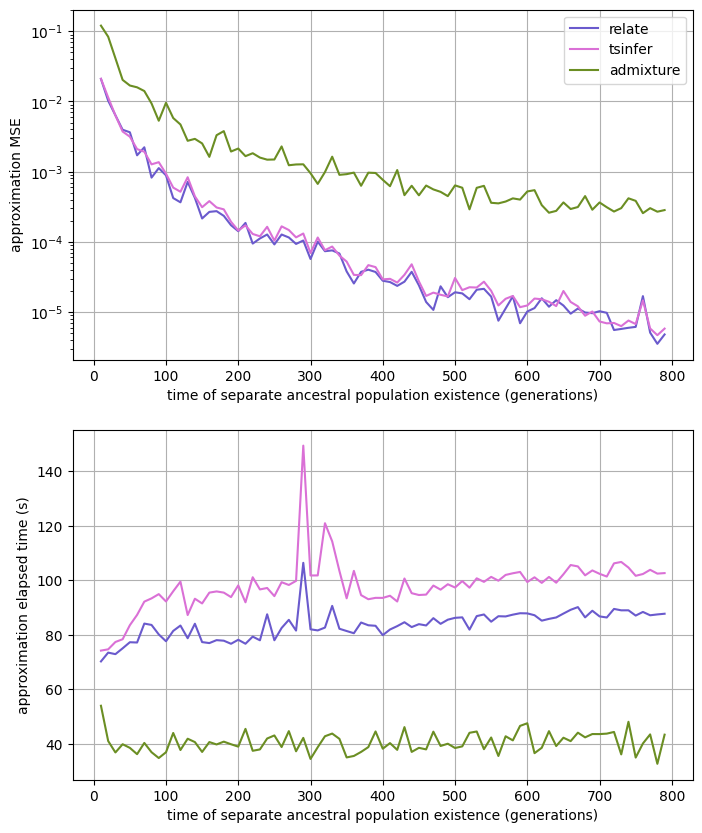

In [11]:
fig, ax = plt.subplots(2, figsize=(8, 10))

labels = ['relate', 'tsinfer', 'admixture']

for lab in labels:
    ax[0].plot(tBC_vals, errors[lab], label=lab, c=colors[lab])
    ax[1].plot(tBC_vals, times[lab], label=lab, c=colors[lab])
if len(admixture_fail) > 0:
    ax[0].scatter(admixture_fail, [1]*len(admixture_fail), c='red', label='admixture fail')
ax[0].legend()
ax[0].set_xlabel("time of separate ancestral population existence (generations)")
ax[0].set_ylabel("approximation MSE")
ax[0].set_yscale('log')
ax[1].set_xlabel("time of separate ancestral population existence (generations)")
ax[1].set_ylabel("approximation elapsed time (s)")
ax[0].grid(zorder=0)
ax[1].grid(zorder=0)
plt.show()

# $K > 2$ популяций

In [3]:
import shutil
import os
import numpy as np
import matplotlib.pyplot as plt
import contextlib
import subprocess
import timeit
from datetime import datetime

from demo import TS_sim, TS_tsinfer, TS_relate


## тесты

In [ ]:

@contextlib.contextmanager
def suppress_output():
    devnull = os.open(os.devnull, os.O_WRONLY)

    old_stdout = os.dup(1)
    old_stderr = os.dup(2)

    os.dup2(devnull, 1)
    os.dup2(devnull, 2)

    try:
        yield
    finally:
        os.dup2(old_stdout, 1)
        os.dup2(old_stderr, 2)

        os.close(old_stdout)
        os.close(old_stderr)
        os.close(devnull)

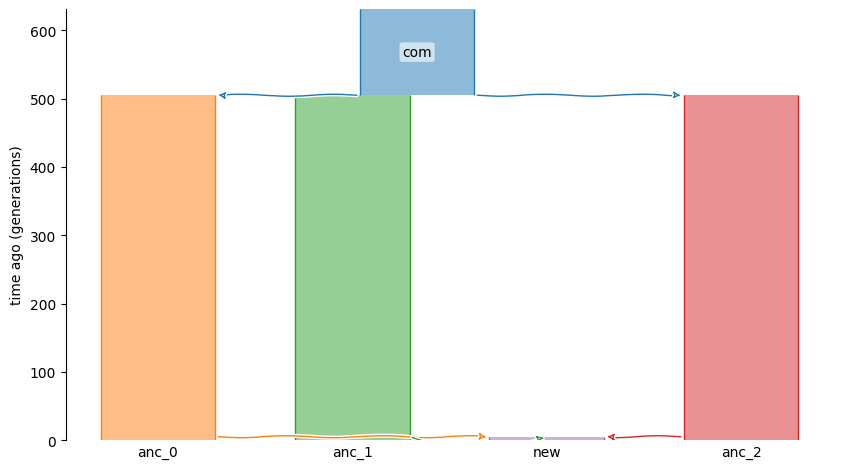

In [4]:
sim = TS_sim(N_samples = np.array([30] * (4)))
sim.dem_pic()

In [14]:
sim.anc_cnt()

In [15]:
alpha, _ = sim.targ_appr()

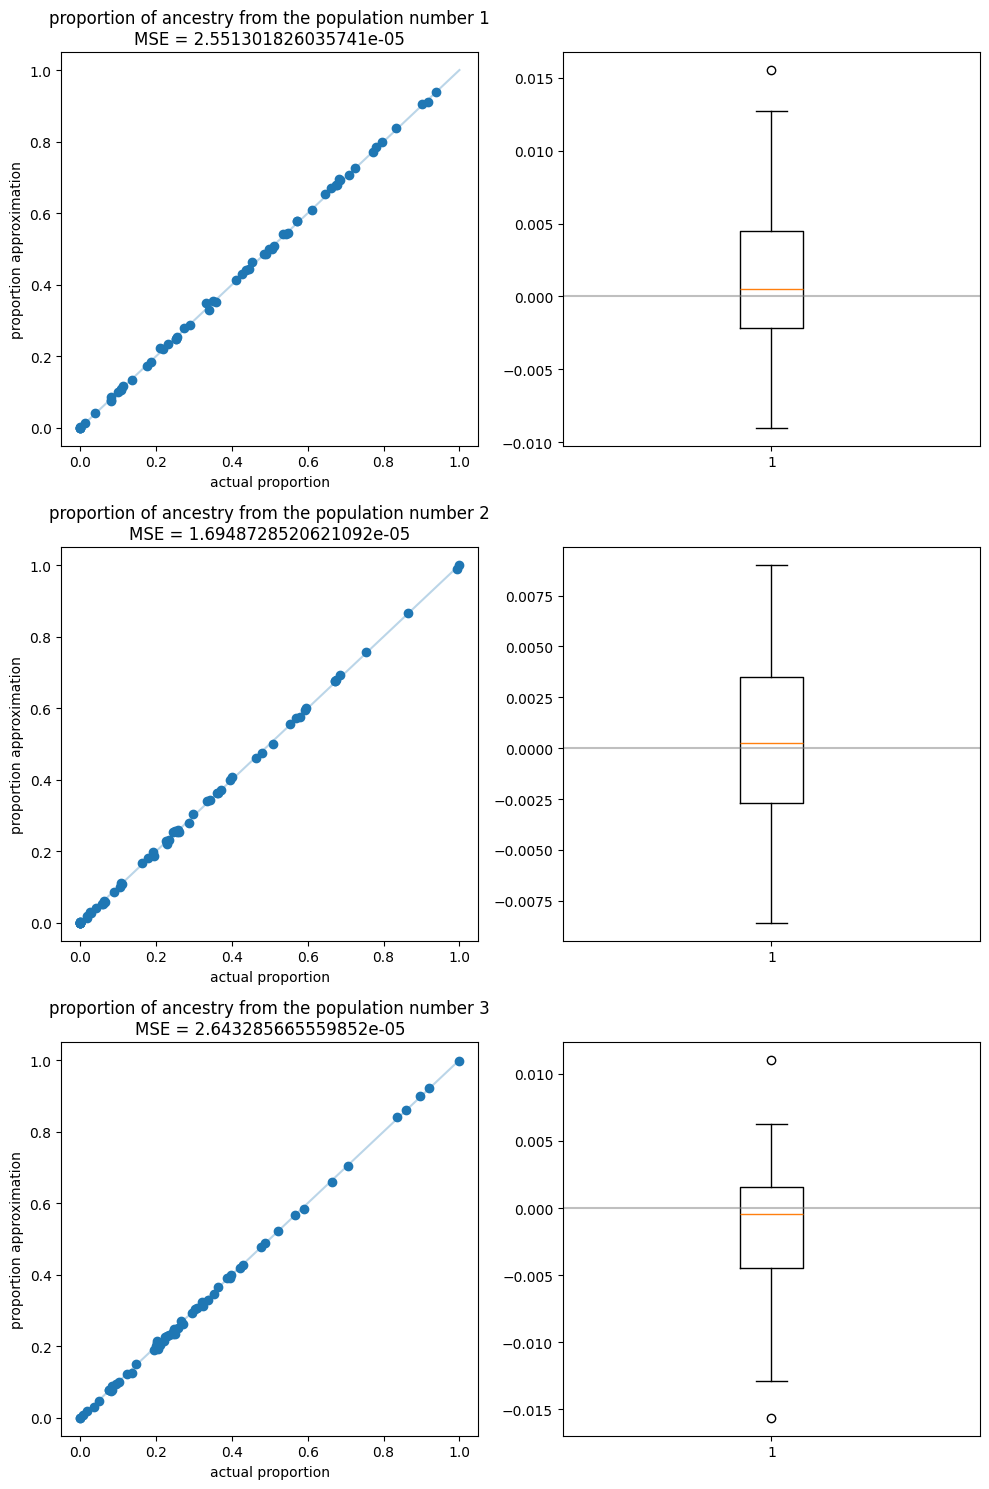

In [20]:
fig, ax = plt.subplots(3,2, figsize=(10, 15))
for pop_id in range (3):
    t_a = sim.true_ancestry[:,pop_id]
    a_a = alpha[:,pop_id]
    ax[pop_id, 0].set_xlabel('actual proportion')
    ax[pop_id, 0].set_ylabel('proportion approximation')
    ax[pop_id, 0].plot([0,1], [0,1], alpha=0.3)
    ax[pop_id, 0].scatter(t_a, a_a)
    ax[pop_id, 0].set_title(f'proportion of ancestry from the population number {sim.ids[pop_id] + 1}\n' + 
                    f'MSE = {np.mean((t_a - a_a)**2)}')

    ax[pop_id, 1].boxplot(a_a - t_a)
    ax[pop_id, 1].axhline(y=0, color='grey', alpha=0.5) 
plt.tight_layout()
plt.show()

In [ ]:
colors = {
            'simulation': 'tan',
            'tsinfer': 'orchid',
            'relate': 'slateblue',
            'admixture': 'olivedrab'
        }

labels = list(colors.keys())

def test_mult(k=2, n=30, Ne=1000):
            
    sim = TS_sim(N_samples = np.array([n] * (k + 1)), 
                 size_com=Ne, size_new=Ne, size_anc = np.array([Ne] * k))
    models = {'simulation':sim}

    with suppress_output():
            run_dir = sim.save_vcf()
            models['tsinfer'] = TS_tsinfer(sim, run_dir)
            models['relate'] = TS_relate(sim, run_dir)

    _, ax = plt.subplots(k,2, figsize=(10, k*5))

    for i,lab in enumerate(models.keys()):
        mod = models[lab]
        mod.anc_cnt()
        alpha, _ = mod.targ_appr()
        for pop_id in range (k):
            t_a = mod.true_ancestry[:,pop_id]
            t_a = (t_a[0::2] + t_a[1::2]) / 2
            a_a = alpha[:,pop_id]
            a_a = (a_a[0::2] + a_a[1::2]) / 2
            ax[pop_id, 0].scatter(t_a, a_a, c=colors[lab], alpha=0.7, label=lab)
            ax[pop_id, 1].boxplot(a_a - t_a, positions=[i])

    with suppress_output():
        subprocess.run([
                "plink/plink", "--vcf",
                run_dir + "/sim.vcf.gz",
                "--double-id", "--make-bed", "--out",
                run_dir + "/sim"
                ], check=True)
    
    pop = ['-'] * sim.N
    cur_id = 0
    for i in range (sim.anc_pops):
        cur_pop = 'POP' + str(i + 1)
        for j in range(sim.N_samples[i]):
            pop[cur_id] = cur_pop
            cur_id += 1

    with open(run_dir + "/sim.pop", "w") as f:
        f.write("\n".join(pop))

    with suppress_output():
        subprocess.run([
            "dist/admixture_macosx-1.3.0/admixture",
            "--supervised",
            run_dir + "/sim.bed",
            str(sim.anc_pops)
            ], check=True)
        
    a = np.loadtxt(f'sim.{k}.Q')
                
    for pop_id in range (k):
        t_a = sim.true_ancestry[:,pop_id]
        t_a = (t_a[0::2] + t_a[1::2]) / 2
        a_a = a[k*n:,pop_id]
        ax[pop_id, 0].scatter(t_a, a_a, c=colors['admixture'], alpha=0.7, label='admixture')
        ax[pop_id, 1].boxplot(a_a - t_a, positions=[3])
        ax[pop_id, 0].set_xlabel('actual proportion')
        ax[pop_id, 0].set_ylabel('proportion approximation')
        ax[pop_id, 0].legend()
        ax[pop_id, 0].plot([0,1], [0,1], alpha=0.3, c='grey')
        ax[pop_id, 0].set_title(f'proportion of ancestry from the population number {sim.ids[pop_id] + 1}\n')
        ax[pop_id, 1].axhline(y=0, color='grey', alpha=0.5) 
        ax[pop_id, 1].set_xticklabels(labels)

    plt.tight_layout()           
    plt.show()

    shutil.rmtree(run_dir)
    os.remove(f'sim.{k}.Q')
    os.remove(f'sim.{k}.P')

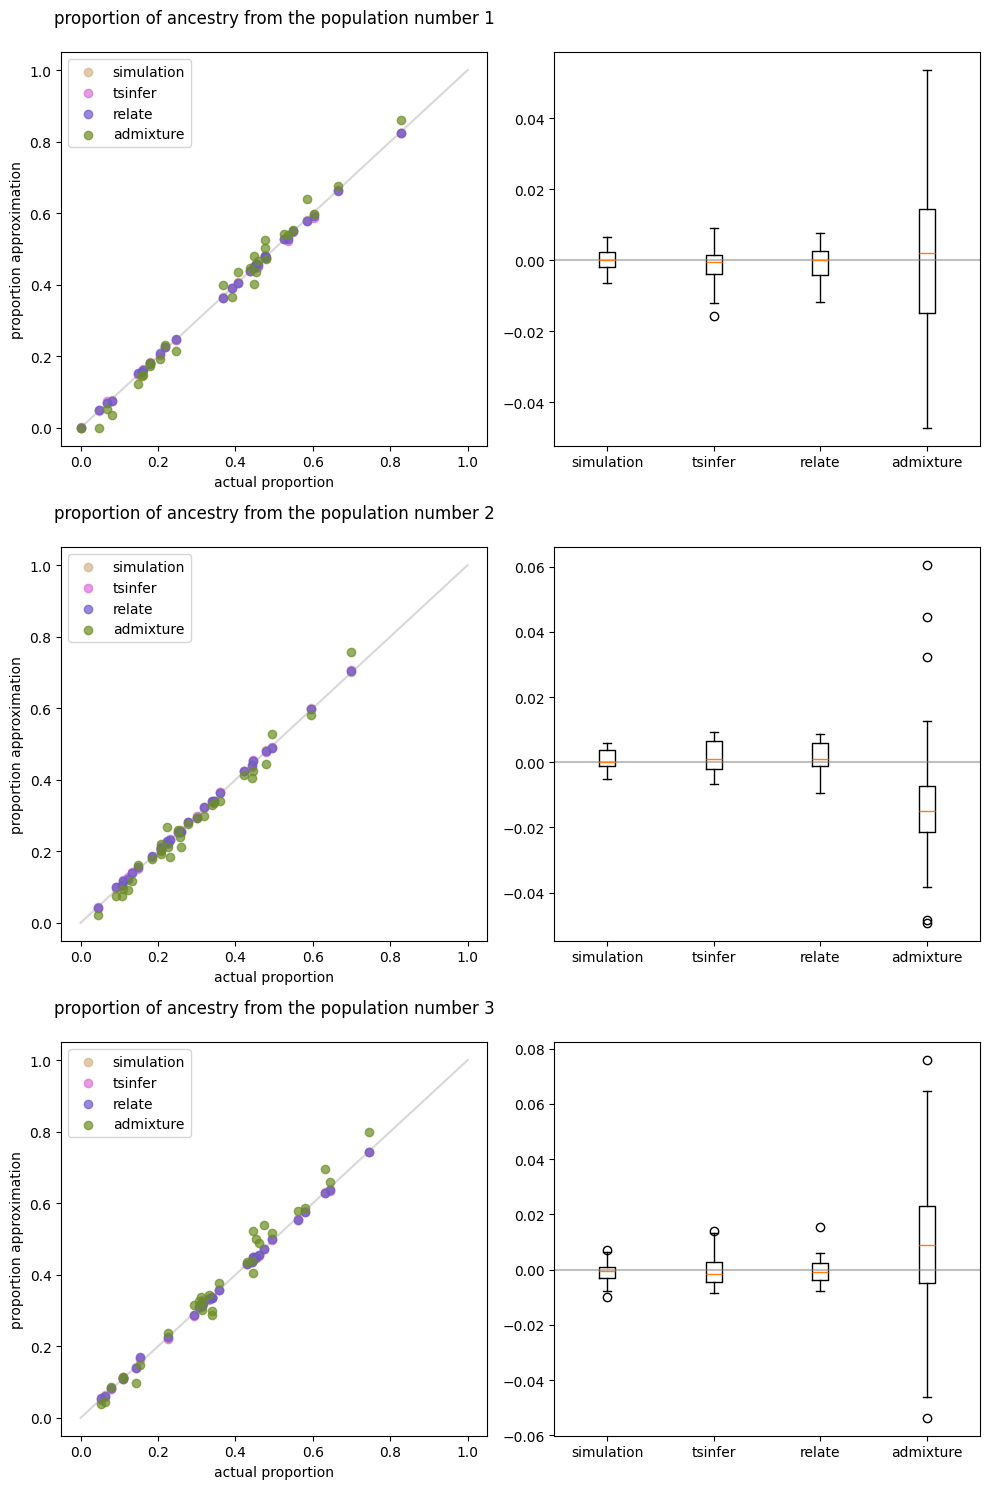

In [48]:
test_mult(k=3)

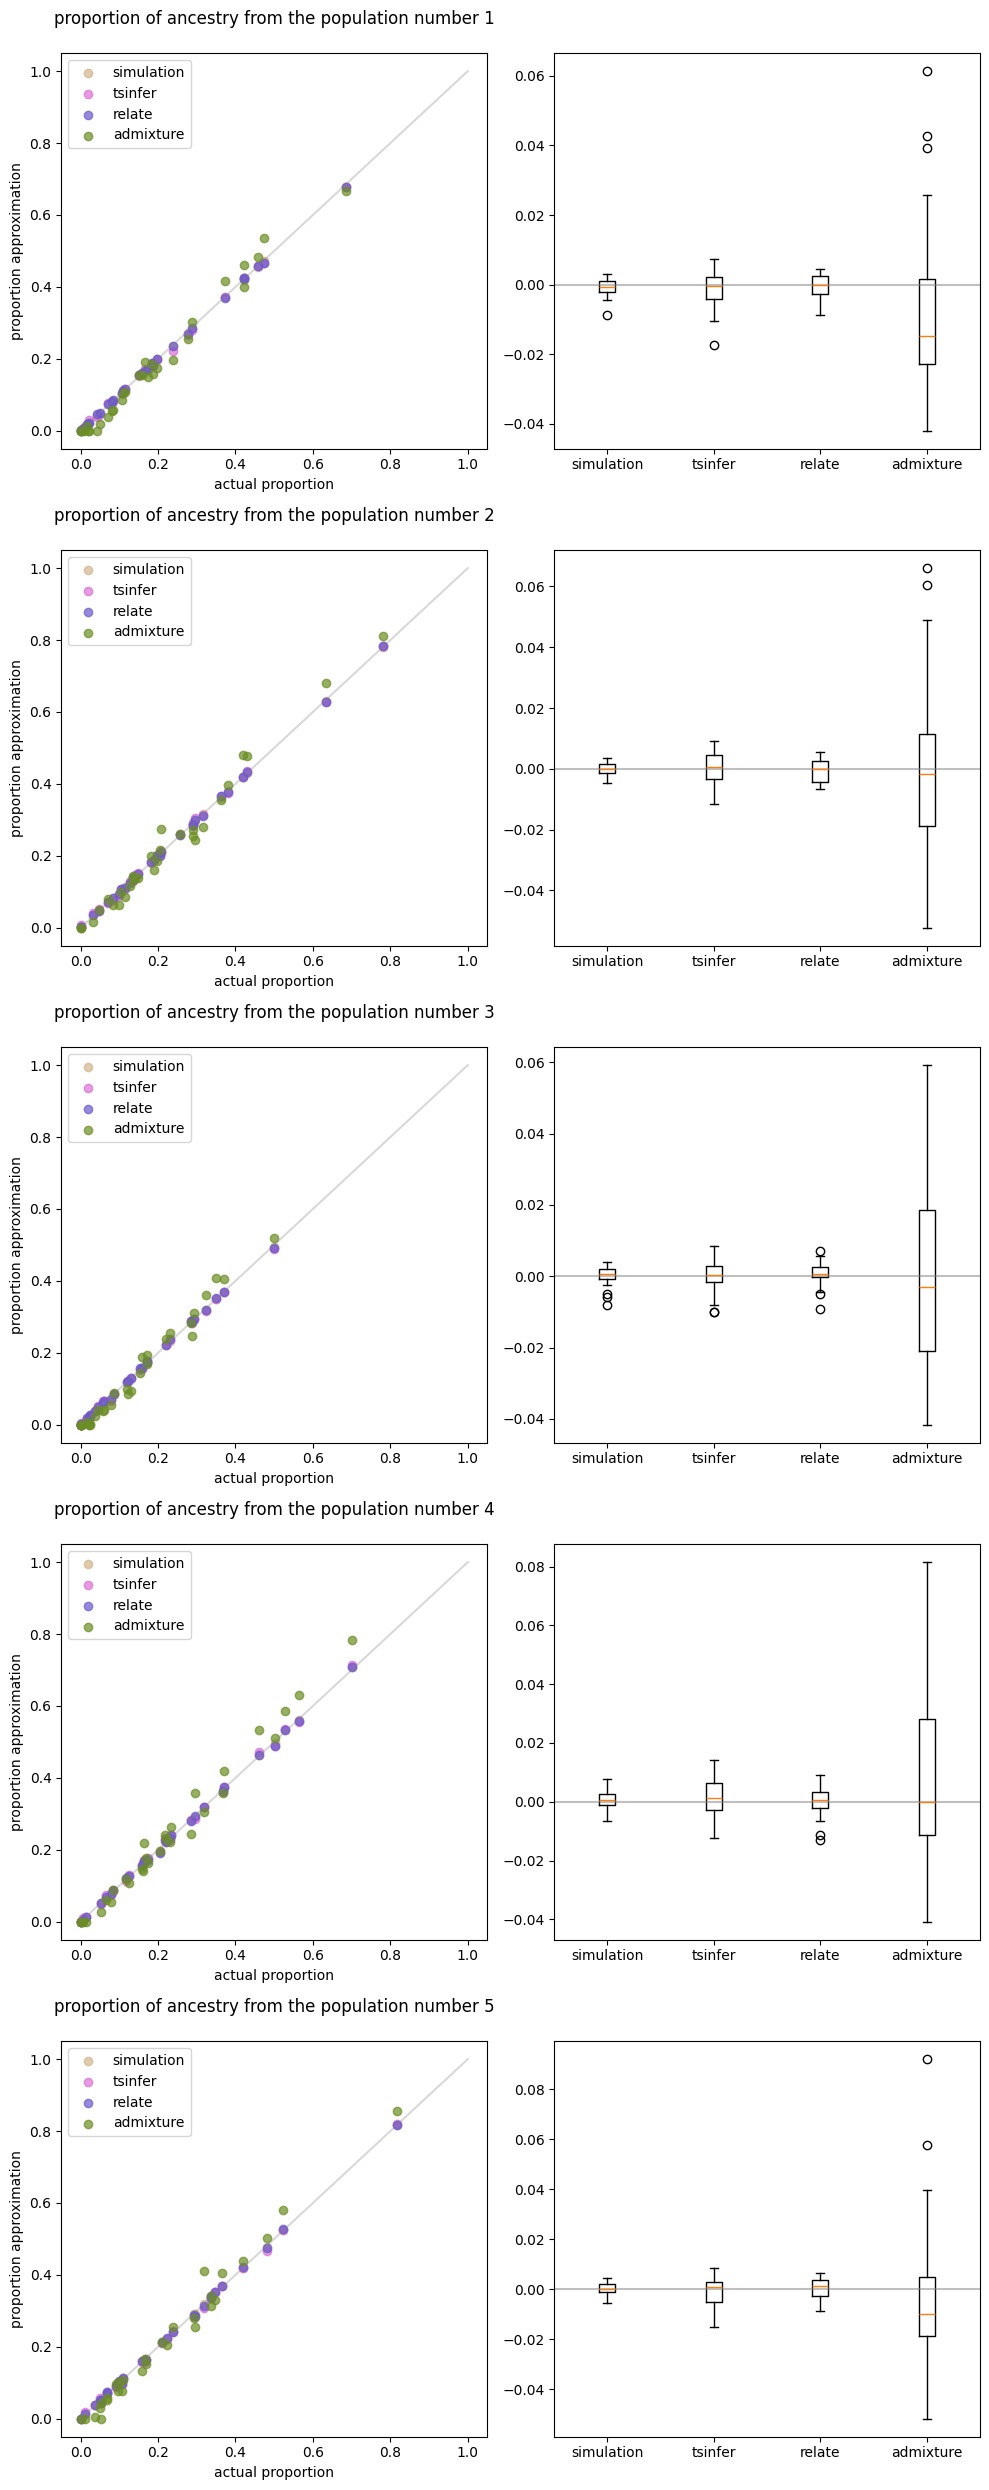

In [51]:
test_mult(k=5)

## нормальные тесты

In [2]:
colors = {
            'simulation': 'tan',
            'tsinfer': 'orchid',
            'relate': 'slateblue',
            'admixture': 'olivedrab'
        }

labels = list(colors.keys())

def compare_mult(t_anc=100, t_new=10, 
                 k=2, n=30, Ne=1000,
                 sim_cnt=False, tsi_cnt=False, 
                 show_results=False, log=False, clear=True):
    def log_msg(message):
        if log:
            print(f"[{datetime.now().strftime('%H:%M:%S')}] {message}", flush=True)

    time = dict()
    approx = dict()

    log_msg("simulating data")

    sim = TS_sim(t_anc=t_anc, t_new=t_new,
                 N_samples = np.array([n] * (k + 1)), 
                 size_com=Ne, size_new=Ne, size_anc=np.array([Ne] * k))
    
    log_msg("saving vcf file")
    with suppress_output():
        run_dir = sim.save_vcf()
    true = (sim.true_ancestry[0::2,:] + sim.true_ancestry[1::2,:]) / 2

    log_msg("data is ready for analysis\n")
    
    time['simulation'] = None
    if sim_cnt:
        log_msg("counting ancestry for the simulated tree sequence")
        sim.anc_cnt()
        alpha, _ = sim.targ_appr()
        approx['simulation'] = (alpha[0::2,:] + alpha[1::2,:]) / 2
        log_msg("simulated tree sequence analysis finished\n")
    else:
        approx['simulation'] = None
    
    if tsi_cnt:
        s = timeit.default_timer()
        log_msg("inferring the tree sequence with tsinfer")
        with suppress_output():
            tsi = TS_tsinfer(sim, run_dir)
        log_msg("counting ancestry for the tsinfer tree sequence")
        tsi.anc_cnt()
        alpha, _ = tsi.targ_appr()
        approx['tsinfer'] = (alpha[0::2,:] + alpha[1::2,:]) / 2
        e = timeit.default_timer()
        log_msg("tsinfer tree sequence analysis finished\n")
        time['tsinfer'] = e - s
    else:
        approx['tsinfer'] = None
        time['tsinfer'] = None

    s = timeit.default_timer()
    log_msg("inferring the tree sequence with relate")
    with suppress_output():
        rel = TS_relate(sim, run_dir)
    log_msg("counting ancestry for the relate tree")
    rel.anc_cnt()
    alpha, _ = rel.targ_appr()
    approx['relate'] = (alpha[0::2,:] + alpha[1::2,:]) / 2
    e = timeit.default_timer()
    log_msg("relate tree sequence analysis finished\n")
    time['relate'] = e - s

    s = timeit.default_timer()
    log_msg("preparing data for ADMIXTURE")
    log_msg("   creating plink file")
    with suppress_output():
        subprocess.run([
                "plink/plink", "--vcf",
                run_dir + "/sim.vcf.gz",
                "--double-id", "--make-bed", "--out",
                run_dir + "/sim"
                ], check=True)
    
    log_msg("   creating pop file")
    pop = ['-'] * sim.N
    cur_id = 0
    for i in range (k):
        cur_pop = 'POP' + str(i + 1)
        for j in range(sim.N_samples[i]):
            pop[cur_id] = cur_pop
            cur_id += 1

    with open(run_dir + "/sim.pop", "w") as f:
        f.write("\n".join(pop))

    log_msg("starting ADMIXTURE")
    attempt = 1
    admixture_success = False
    while attempt <= 3 and not admixture_success:
        log_msg(f"  ADMIXTURE attempt {attempt}")
        try:
            with suppress_output():
                subprocess.run([
                    "dist/admixture_macosx-1.3.0/admixture",
                    "--supervised",
                    run_dir + "/sim.bed",
                    str(sim.anc_pops)
                    ], check=True)
            admixture_success = True
            log_msg("       ADMIXTURE finished")
        except Exception as e:
            log_msg(f"      ADMIXTURE failed with error: {e}")
            admixture_success = False
    e = timeit.default_timer()
    time['admixture'] = e - s
    if admixture_success:
        a = np.loadtxt(f'sim.{k}.Q')
        approx['admixture'] = a[k*n:,:]
        log_msg("ADMIXTURE data saved\n")
    else:
        log_msg("all ADMIXTURE attempts failed\n")
        approx['admixture'] = None


    if clear:
        shutil.rmtree(run_dir)
        os.remove(f'sim.{k}.Q')
        os.remove(f'sim.{k}.P')
        log_msg("all data cleared\n\n")


    if show_results:
        _, ax = plt.subplots(k,2, figsize=(10, k*5))
        
        for i,lab in enumerate(labels):
            t = time[lab]
            if t is not None:
                t = time[lab]
                t_int = int(t) // 60
                h = t_int // 60
                m = t_int % 60
                s = t - h * 3600 - m * 60
                t_str = f'{m} min {s:.2f} s'
                if h > 0:
                    t_str = f'{h} h' + t_str
                print(f'method using {lab} took ' + t_str)

            alpha = approx[lab]
            if alpha is not None:
                for pop_id in range (k):
                    t_a = true[:,pop_id]
                    a_a = alpha[:,pop_id]
                    ax[pop_id, 0].scatter(t_a, a_a, c=colors[lab], alpha=0.6, label=lab)
                    ax[pop_id, 1].boxplot(a_a - t_a, positions=[i])

        for pop_id in range (k):
            ax[pop_id, 0].set_xlabel('actual proportion')
            ax[pop_id, 0].set_ylabel('proportion approximation')
            ax[pop_id, 0].legend()
            ax[pop_id, 0].plot([0,1], [0,1], alpha=0.3, c='grey')
            ax[pop_id, 0].set_title(f'proportion of ancestry from the population number {sim.ids[pop_id] + 1}\n')
            ax[pop_id, 1].axhline(y=0, color='grey', alpha=0.5) 
            ax[pop_id, 1].set_xticklabels(labels)

        plt.tight_layout()           
        plt.show()
        return

    return true, approx, time

### проверка связи

[11:04:28] simulating data
[11:04:31] saving vcf file
[11:04:38] data is ready for analysis

[11:04:38] counting ancestry for the simulated tree sequence
[11:06:43] simulated tree sequence analysis finished

[11:06:43] inferring the tree sequence with tsinfer
[11:07:04] counting ancestry for the tsinfer tree sequence
[11:07:53] tsinfer tree sequence analysis finished

[11:07:53] inferring the tree sequence with relate
[11:08:32] counting ancestry for the relate tree
[11:08:40] relate tree sequence analysis finished

[11:08:40] preparing data for ADMIXTURE
[11:08:40]    creating plink file
[11:08:40]    creating pop file
[11:08:40] starting ADMIXTURE
[11:08:40]   ADMIXTURE attempt 1
[11:09:19]        ADMIXTURE finished
[11:09:19] ADMIXTURE data saved

[11:09:19] all data cleared


method using tsinfer took 1 min 9.84 s
method using relate took 0 min 47.29 s
method using admixture took 0 min 39.28 s


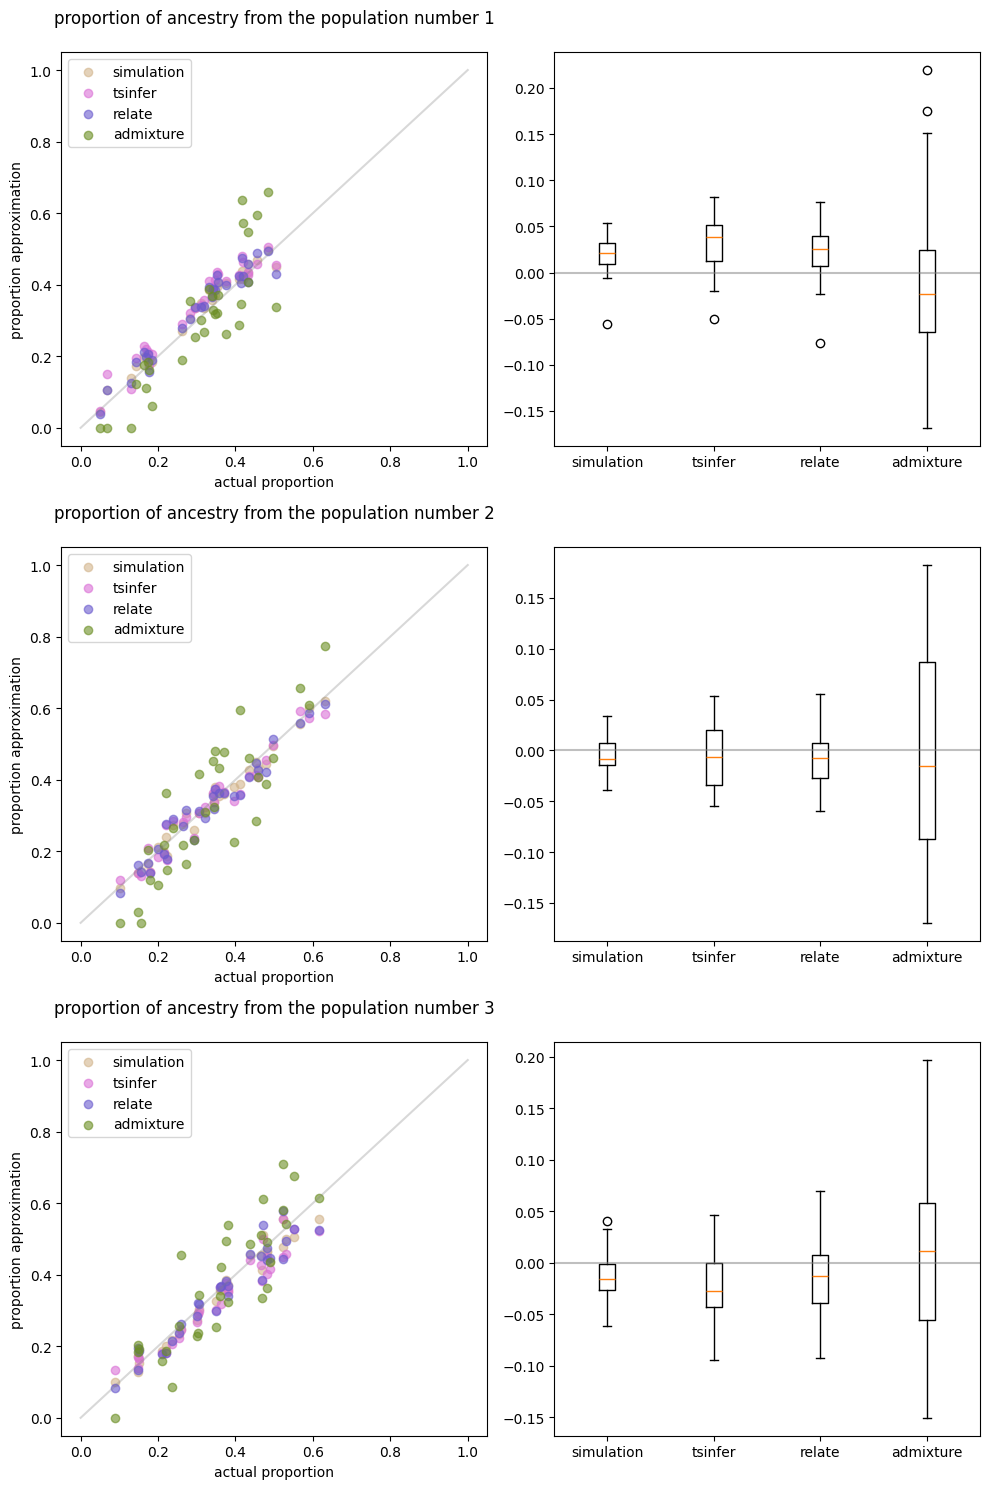

In [65]:
compare_mult(k=3, sim_cnt=True, tsi_cnt=True, show_results=True, log=True)

[11:09:20] simulating data
[11:09:24] saving vcf file
[11:09:33] data is ready for analysis

[11:09:33] counting ancestry for the simulated tree sequence
[11:15:23] simulated tree sequence analysis finished

[11:15:23] inferring the tree sequence with tsinfer
[11:16:11] counting ancestry for the tsinfer tree sequence
[11:19:27] tsinfer tree sequence analysis finished

[11:19:27] inferring the tree sequence with relate
[11:22:05] counting ancestry for the relate tree
[11:22:33] relate tree sequence analysis finished

[11:22:33] preparing data for ADMIXTURE
[11:22:33]    creating plink file
[11:22:33]    creating pop file
[11:22:33] starting ADMIXTURE
[11:22:33]   ADMIXTURE attempt 1
[11:27:46]        ADMIXTURE finished
[11:27:46] ADMIXTURE data saved

[11:27:46] all data cleared


method using tsinfer took 4 min 4.63 s
method using relate took 3 min 5.53 s
method using admixture took 5 min 13.25 s


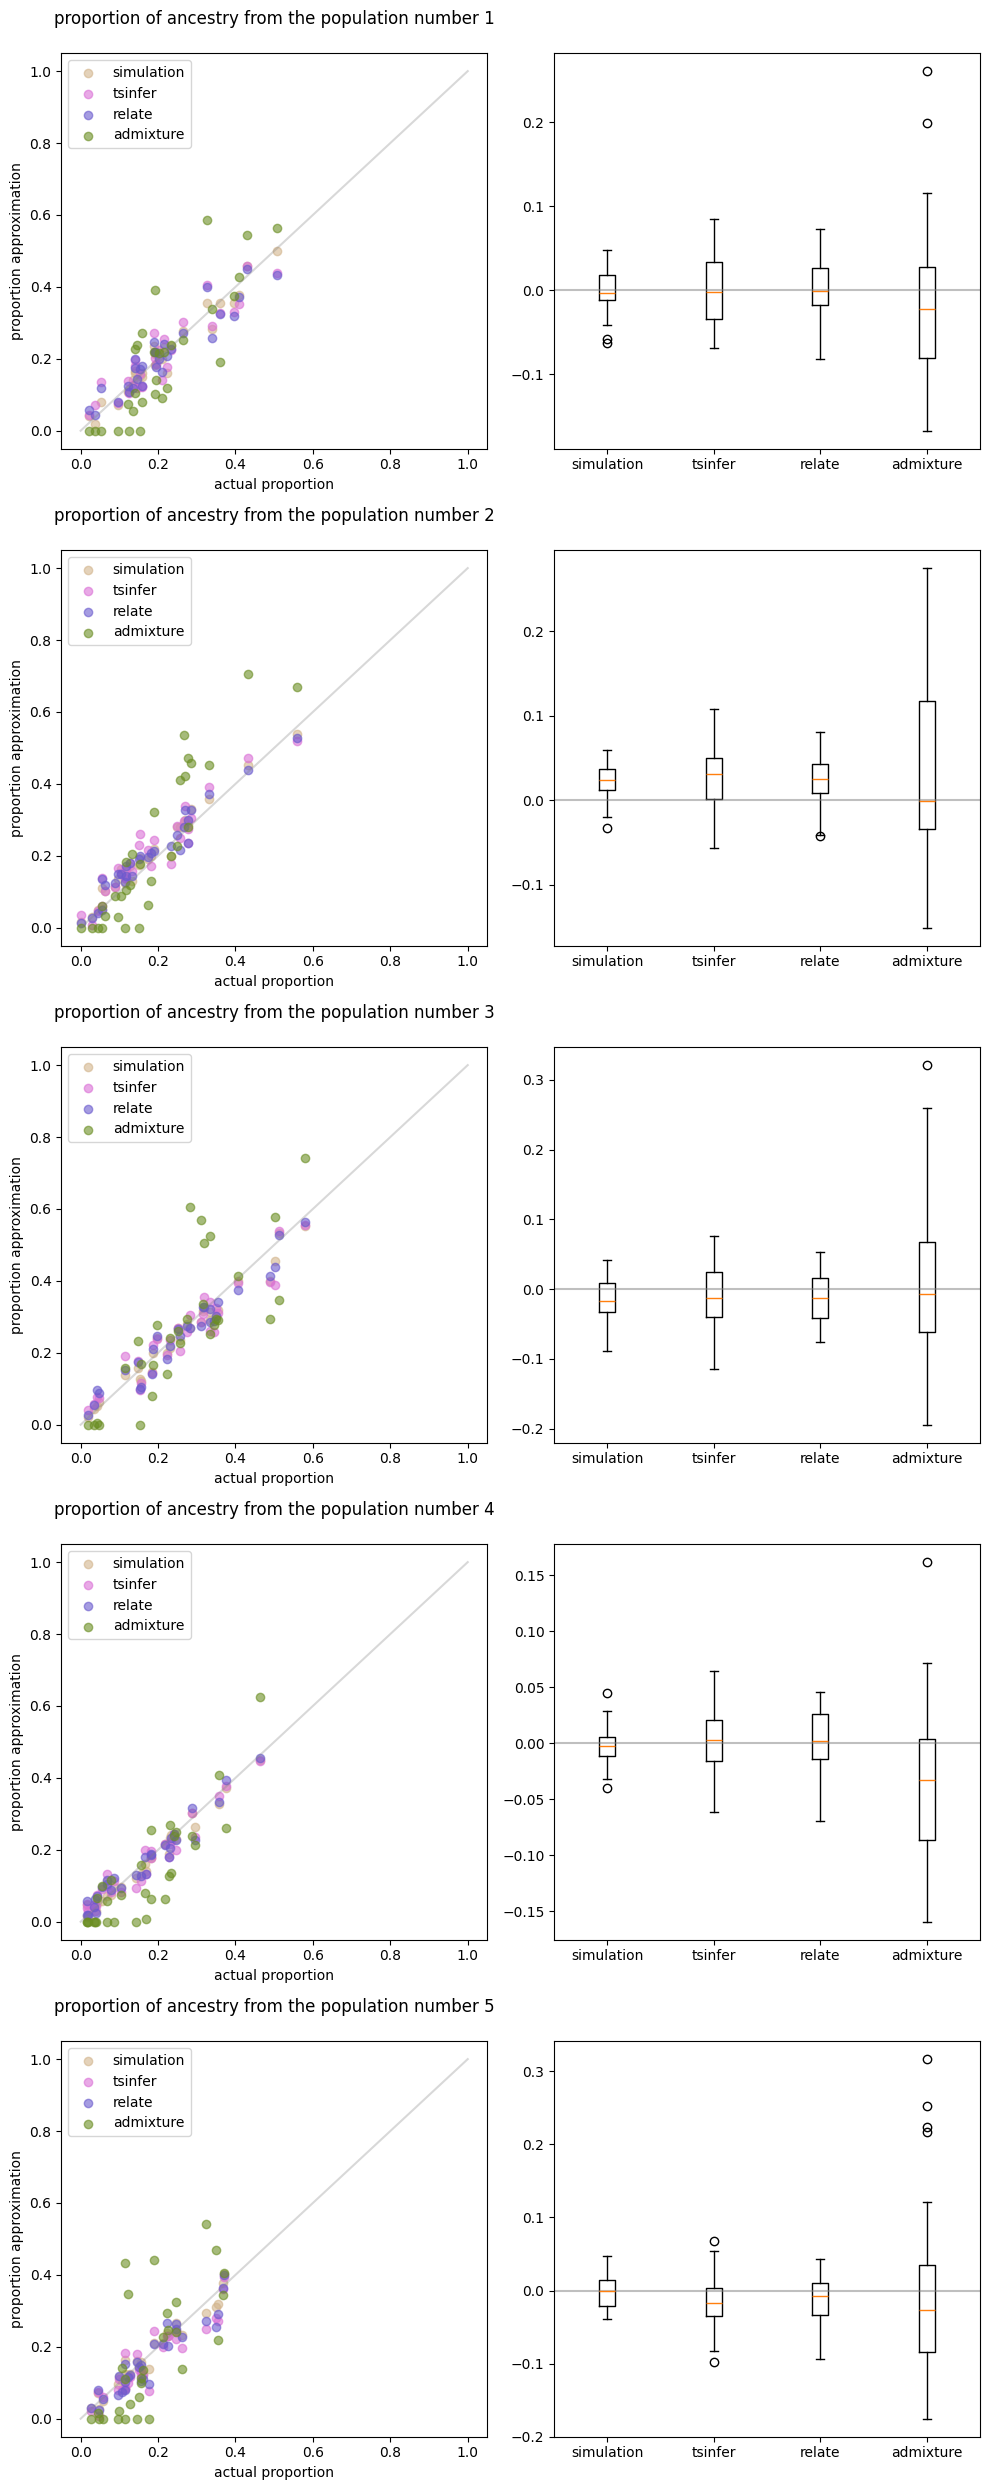

In [66]:
compare_mult(k=5, sim_cnt=True, tsi_cnt=True, show_results=True, log=True)

[11:33:09] simulating data
[11:33:16] saving vcf file
[11:33:30] data is ready for analysis

[11:33:30] counting ancestry for the simulated tree sequence
[11:38:20] simulated tree sequence analysis finished

[11:38:20] inferring the tree sequence with tsinfer
[11:39:16] counting ancestry for the tsinfer tree sequence
[11:41:16] tsinfer tree sequence analysis finished

[11:41:16] inferring the tree sequence with relate
[11:42:50] counting ancestry for the relate tree
[11:43:08] relate tree sequence analysis finished

[11:43:08] preparing data for ADMIXTURE
[11:43:08]    creating plink file
[11:43:09]    creating pop file
[11:43:09] starting ADMIXTURE
[11:43:09]   ADMIXTURE attempt 1
[11:44:29]        ADMIXTURE finished
[11:44:29] ADMIXTURE data saved

[11:44:29] all data cleared


method using tsinfer took 2 min 56.74 s
method using relate took 1 min 51.99 s
method using admixture took 1 min 20.70 s


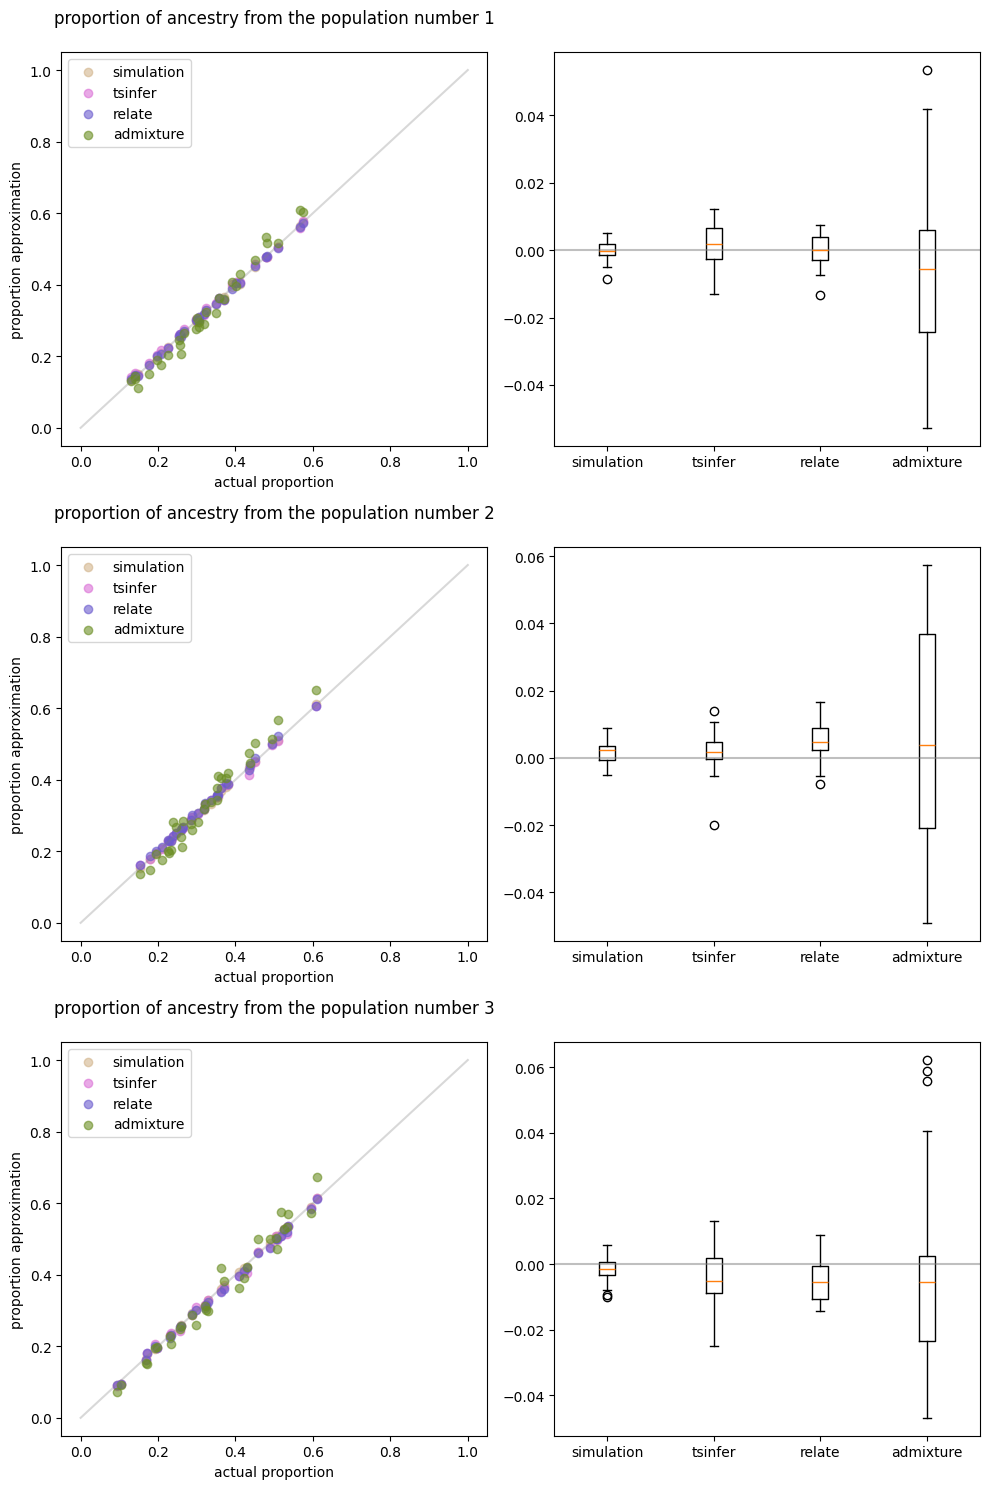

In [68]:
compare_mult(k=3, t_anc=500,
             sim_cnt=True, tsi_cnt=True, show_results=True, log=True)

[11:44:30] simulating data
[11:44:40] saving vcf file
[11:45:01] data is ready for analysis

[11:45:01] counting ancestry for the simulated tree sequence
[11:54:45] simulated tree sequence analysis finished

[11:54:45] inferring the tree sequence with tsinfer
[11:55:57] counting ancestry for the tsinfer tree sequence
[12:00:26] tsinfer tree sequence analysis finished

[12:00:26] inferring the tree sequence with relate
[12:04:18] counting ancestry for the relate tree
[12:04:58] relate tree sequence analysis finished

[12:04:58] preparing data for ADMIXTURE
[12:04:58]    creating plink file
[12:04:59]    creating pop file
[12:04:59] starting ADMIXTURE
[12:04:59]   ADMIXTURE attempt 1
[12:11:11]        ADMIXTURE finished
[12:11:11] ADMIXTURE data saved

[12:11:11] all data cleared


method using tsinfer took 5 min 41.17 s
method using relate took 4 min 31.75 s
method using admixture took 6 min 13.48 s


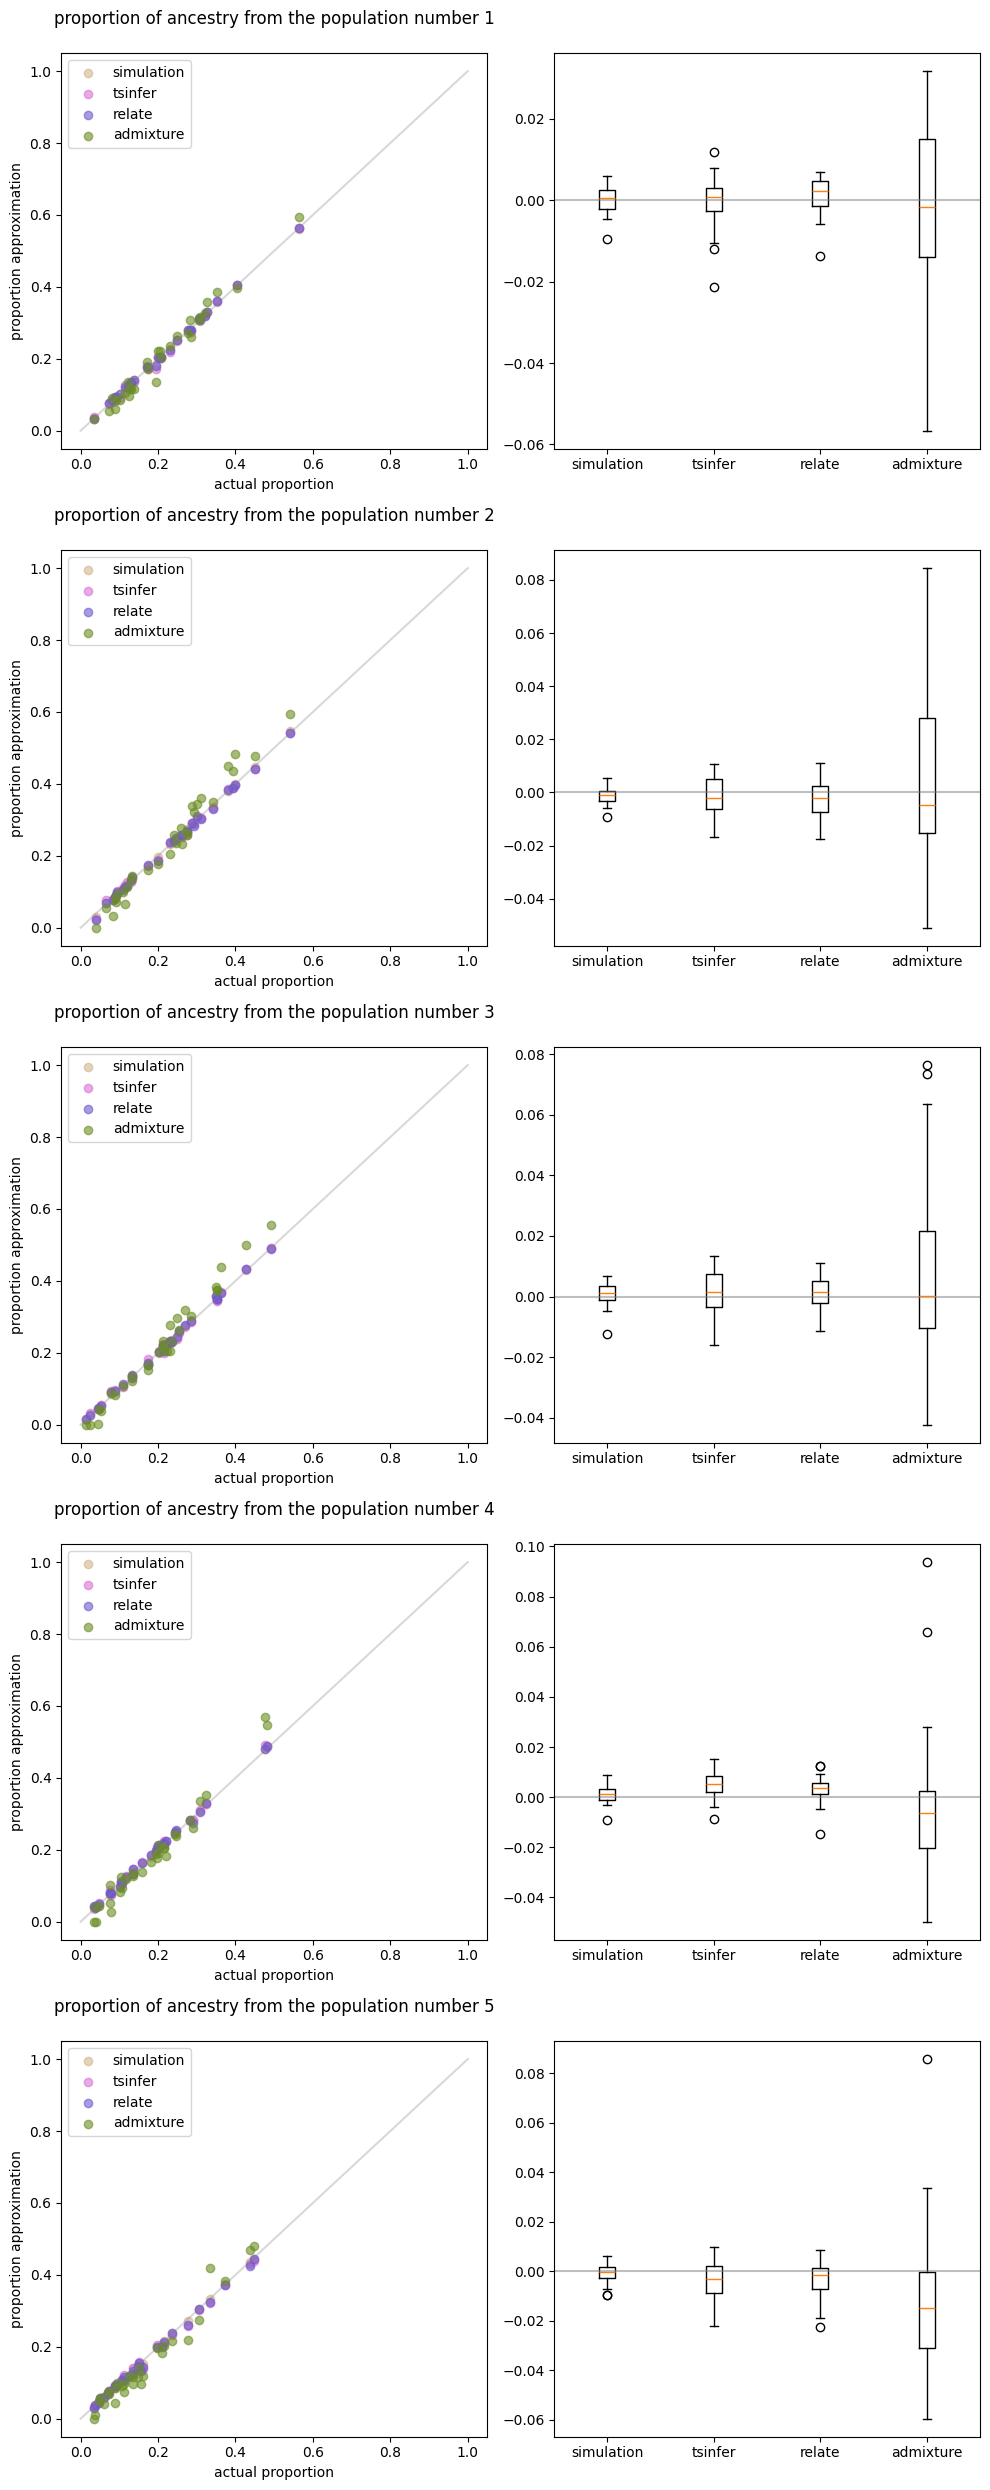

In [69]:
compare_mult(k=5, t_anc=500,
             sim_cnt=True, tsi_cnt=True, show_results=True, log=True)

### $N_e = 10^4$

[12:11:12] simulating data


[12:13:15] saving vcf file
[12:14:34] data is ready for analysis

[12:14:34] counting ancestry for the simulated tree sequence
[12:41:33] simulated tree sequence analysis finished

[12:41:33] inferring the tree sequence with tsinfer
[12:53:14] counting ancestry for the tsinfer tree sequence
[13:03:44] tsinfer tree sequence analysis finished

[13:03:44] inferring the tree sequence with relate
[13:14:37] counting ancestry for the relate tree
[13:16:43] relate tree sequence analysis finished

[13:16:43] preparing data for ADMIXTURE
[13:16:43]    creating plink file
[13:16:44]    creating pop file
[13:16:44] starting ADMIXTURE
[13:16:44]   ADMIXTURE attempt 1
[13:31:15]        ADMIXTURE finished
[13:31:15] ADMIXTURE data saved

[13:31:15] all data cleared


method using tsinfer took 22 min 11.18 s
method using relate took 12 min 58.43 s
method using admixture took 14 min 32.34 s


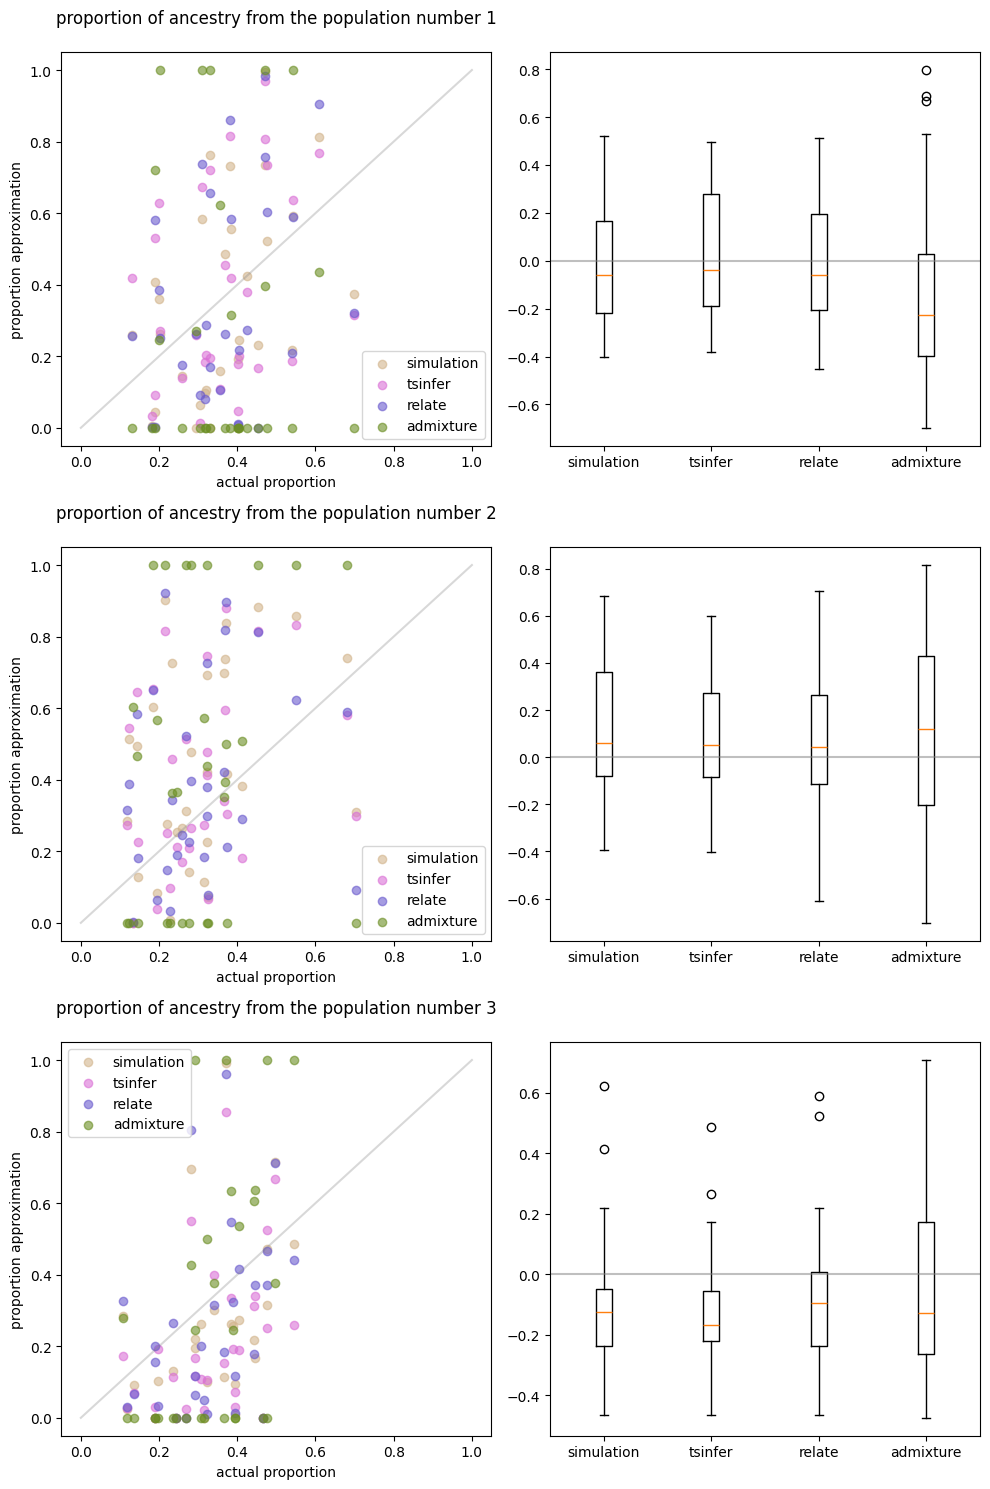

In [70]:
compare_mult(k=3, Ne=10000, t_anc=30,
             sim_cnt=True, tsi_cnt=True, show_results=True, log=True)

[13:31:16] simulating data
[13:32:32] saving vcf file
[13:33:28] data is ready for analysis

[13:33:28] counting ancestry for the simulated tree sequence
[13:53:06] simulated tree sequence analysis finished

[13:53:06] inferring the tree sequence with tsinfer
[14:08:01] counting ancestry for the tsinfer tree sequence
[14:16:38] tsinfer tree sequence analysis finished

[14:16:38] inferring the tree sequence with relate
[14:23:46] counting ancestry for the relate tree
[14:25:04] relate tree sequence analysis finished

[14:25:04] preparing data for ADMIXTURE
[14:25:04]    creating plink file
[14:25:05]    creating pop file
[14:25:05] starting ADMIXTURE
[14:25:05]   ADMIXTURE attempt 1
[14:31:31]        ADMIXTURE finished
[14:31:31] ADMIXTURE data saved

[14:31:31] all data cleared


method using tsinfer took 23 min 31.93 s
method using relate took 8 min 26.48 s
method using admixture took 6 min 26.59 s


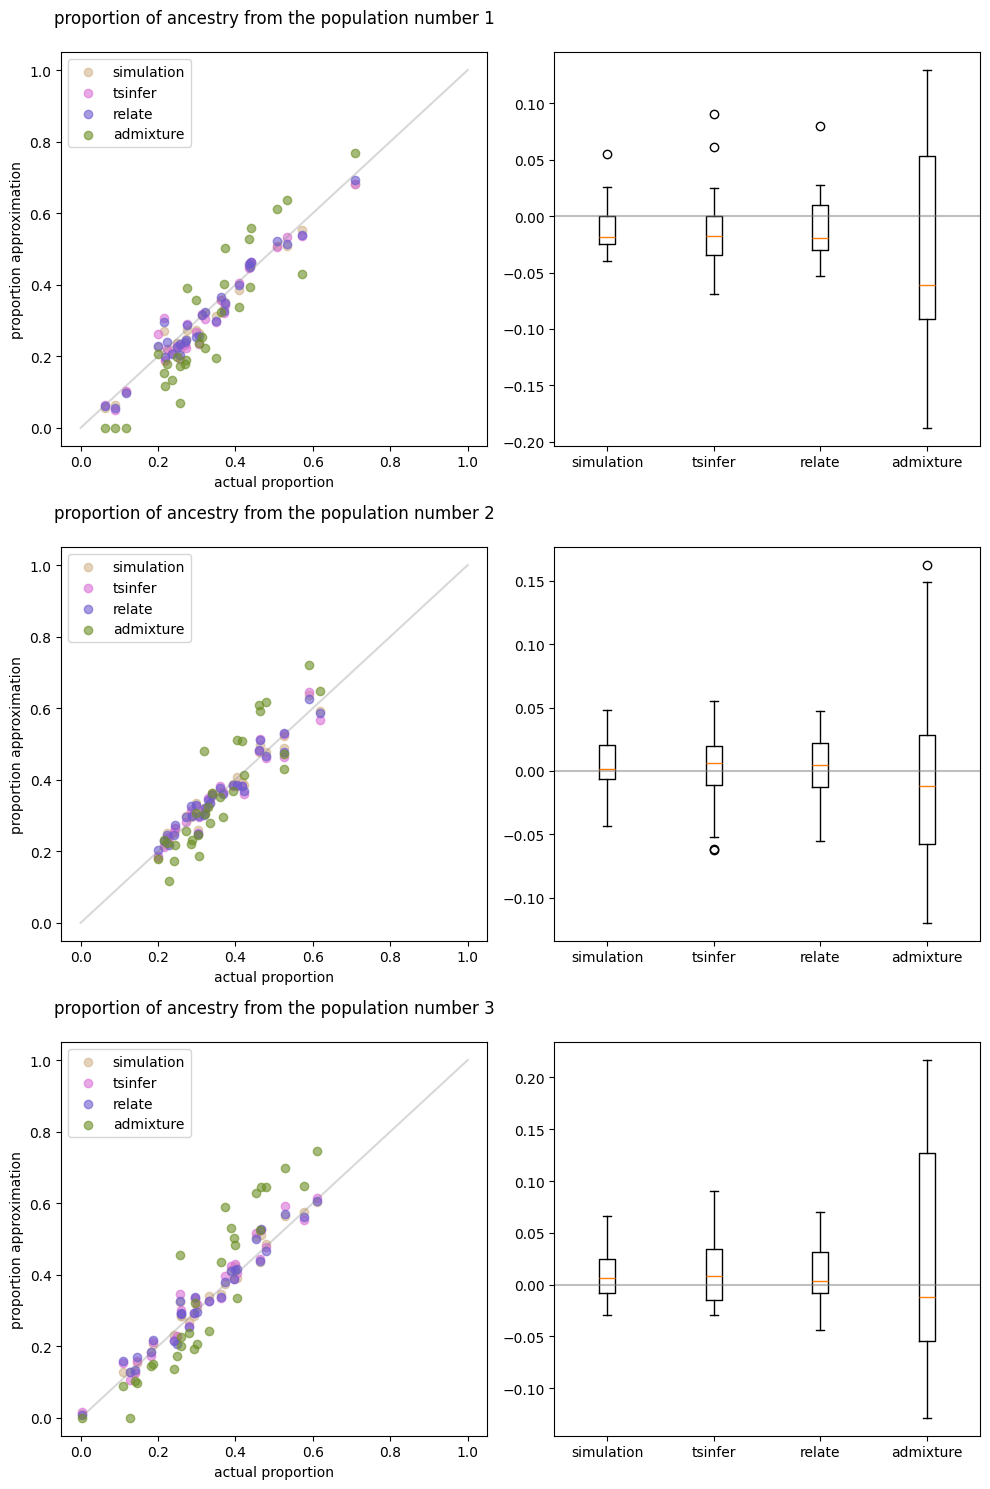

In [71]:
compare_mult(k=3, Ne=10000, t_anc=500,
             sim_cnt=True, tsi_cnt=True, show_results=True, log=True)